# AI-Powered Job Market Intelligence & Salary Prediction System
## Step 5: Salary Prediction Model Development & Evaluation

**Target Notebook:** `notebooks/05_model_training.ipynb`  
**Core Module:** `src/salary_model.py`  
**Input Splits:** `data/processed/X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv`  
**Feature Pipeline:** `models/feature_pipeline.joblib` (113 transformed features)  

### Objectives & Rigorous ML Methodology:
1. **Zero Data Leakage:** Ensure test sets remain completely unseen during training and feature encoding. Target variables and salary-derived fields are strictly excluded from predictors.
2. **Target Transformation Comparison:** Benchmark candidate models on both raw target (`salary_mid_lpa`) and log-transformed target (`log1p(salary_mid_lpa)`) with `expm1` inverse mapping to evaluate right-tail error suppression.
3. **Multi-Model Benchmark:** Train and evaluate 5 core algorithms using 5-fold cross-validation on `X_train` and out-of-sample evaluation on `X_test`:
   - Linear Regression
   - Decision Tree Regressor
   - Random Forest Regressor
   - Gradient Boosting Regressor
   - XGBoost Regressor
4. **Hyperparameter Tuning:** Conduct `RandomizedSearchCV` on the best algorithm across tree depth, learning rate, subsampling, and leaf regularization.
5. **Interpretability & Error Diagnostics:** Extract feature importances, plot actual vs. predicted values, inspect residual distributions, check for heteroscedasticity, and slice errors by seniority tier and role.
6. **Production Artifact Persistence:** Save the tuned regressor, the full end-to-end inference pipeline, model metadata, feature importances, and diagnostic figures to `models/` and `reports/figures/model_evaluation/`.

In [1]:
# 1. Environment Setup & Library Imports
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Ensure project root is in sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

from src.salary_model import SalaryPredictor, predict_salary, LIMITATIONS_DISCLAIMER

# Configure visual aesthetics
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print('Model training environment initialized successfully.')

Model training environment initialized successfully.


### 2. Ingestion of Train/Test Splits and Preprocessing Pipeline
Loading pre-split data from `data/processed/` and the serialized `feature_pipeline.joblib`.

In [2]:
# Define directories
data_dir = os.path.join('..', 'data', 'processed') if os.path.exists(os.path.join('..', 'data', 'processed')) else os.path.join('data', 'processed')
models_dir = os.path.join('..', 'models') if os.path.exists(os.path.join('..', 'models')) else os.path.join('models')
figures_dir = os.path.join('..', 'reports', 'figures', 'model_evaluation') if os.path.exists(os.path.join('..', 'reports', 'figures', 'model_evaluation')) else os.path.join('reports', 'figures', 'model_evaluation')
os.makedirs(figures_dir, exist_ok=True)

# Load splits
X_train = pd.read_csv(os.path.join(data_dir, 'X_train.csv'))
X_test = pd.read_csv(os.path.join(data_dir, 'X_test.csv'))
y_train = pd.read_csv(os.path.join(data_dir, 'y_train.csv'))['salary_mid_lpa'].values
y_test = pd.read_csv(os.path.join(data_dir, 'y_test.csv'))['salary_mid_lpa'].values

# Load feature preprocessor pipeline
feature_pipeline = joblib.load(os.path.join(models_dir, 'feature_pipeline.joblib'))

with open(os.path.join(models_dir, 'feature_metadata.json'), 'r') as f:
    feat_meta = json.load(f)
feature_names = feat_meta['feature_names']

print(f'Train samples: {len(X_train):,} | Test samples: {len(X_test):,}')
print(f'Raw feature columns: {X_train.shape[1]} | Transformed feature dimensions: {len(feature_names)}')
print(f'Target summary (Train): Mean = {np.mean(y_train):.2f} LPA, Median = {np.median(y_train):.2f} LPA, Std = {np.std(y_train):.2f} LPA')

Train samples: 14,047 | Test samples: 3,512
Raw feature columns: 16 | Transformed feature dimensions: 113
Target summary (Train): Mean = 12.28 LPA, Median = 10.69 LPA, Std = 7.10 LPA


### 3. Feature Transformation via Scikit-Learn Pipeline
Applying `feature_pipeline.transform(...)` to generate numerical matrices.

In [3]:
X_train_trans = feature_pipeline.transform(X_train)
X_test_trans = feature_pipeline.transform(X_test)

if hasattr(X_train_trans, 'toarray'):
    X_train_trans = X_train_trans.toarray()
    X_test_trans = X_test_trans.toarray()

print(f'X_train_trans shape: {X_train_trans.shape}')
print(f'X_test_trans shape: {X_test_trans.shape}')
print(f'Any nulls in transformed train: {np.isnan(X_train_trans).any()}')
print(f'Any nulls in transformed test: {np.isnan(X_test_trans).any()}')

X_train_trans shape: (14047, 113)
X_test_trans shape: (3512, 113)
Any nulls in transformed train: False
Any nulls in transformed test: False


### 4. Multi-Algorithm Benchmarking & Target Formulation Comparison
Evaluating Linear Regression, Decision Tree, Random Forest, Gradient Boosting, and XGBoost under both Raw Target and Log1p Transformed Target via 5-fold cross-validation.

In [4]:
base_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, min_samples_split=10, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=4, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=120, max_depth=5, learning_rate=0.08, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=150, max_depth=5, learning_rate=0.07, subsample=0.85, colsample_bytree=0.85, random_state=42, n_jobs=-1),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}

benchmark_records = []
cv_box_data = {}

# Evaluate Raw Target
for name, model in base_models.items():
    cv_res = cross_validate(model, X_train_trans, y_train, cv=kf, scoring=scoring, n_jobs=-1)
    cv_mae = -cv_res['test_mae'].mean()
    cv_rmse = -cv_res['test_rmse'].mean()
    cv_r2 = cv_res['test_r2'].mean()
    cv_box_data[f'{name} (Raw)'] = -cv_res['test_mae']

    model.fit(X_train_trans, y_train)
    preds = model.predict(X_test_trans)
    test_mae = mean_absolute_error(y_test, preds)
    test_mse = mean_squared_error(y_test, preds)
    test_rmse = np.sqrt(test_mse)
    test_r2 = r2_score(y_test, preds)

    benchmark_records.append({
        'Model': name,
        'Target Formulation': 'Raw (salary_mid_lpa)',
        'CV MAE (LPA)': round(cv_mae, 2),
        'CV RMSE (LPA)': round(cv_rmse, 2),
        'CV R2': round(cv_r2, 4),
        'Test MAE (LPA)': round(test_mae, 2),
        'Test MSE': round(test_mse, 2),
        'Test RMSE (LPA)': round(test_rmse, 2),
        'Test R2': round(test_r2, 4),
    })

# Evaluate Log-Transformed Target
for name, model in base_models.items():
    ttr = TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)
    cv_res = cross_validate(ttr, X_train_trans, y_train, cv=kf, scoring=scoring, n_jobs=-1)
    cv_mae = -cv_res['test_mae'].mean()
    cv_rmse = -cv_res['test_rmse'].mean()
    cv_r2 = cv_res['test_r2'].mean()
    cv_box_data[f'{name} (log1p)'] = -cv_res['test_mae']

    ttr.fit(X_train_trans, y_train)
    preds = ttr.predict(X_test_trans)
    test_mae = mean_absolute_error(y_test, preds)
    test_mse = mean_squared_error(y_test, preds)
    test_rmse = np.sqrt(test_mse)
    test_r2 = r2_score(y_test, preds)

    benchmark_records.append({
        'Model': f'{name} (log1p)',
        'Target Formulation': 'Log-Transformed (log1p)',
        'CV MAE (LPA)': round(cv_mae, 2),
        'CV RMSE (LPA)': round(cv_rmse, 2),
        'CV R2': round(cv_r2, 4),
        'Test MAE (LPA)': round(test_mae, 2),
        'Test MSE': round(test_mse, 2),
        'Test RMSE (LPA)': round(test_rmse, 2),
        'Test R2': round(test_r2, 4),
    })

comparison_df = pd.DataFrame(benchmark_records).sort_values(by='Test RMSE (LPA)', ascending=True).reset_index(drop=True)
comparison_df

,Model,Target Formulation,CV MAE (LPA),CV RMSE (LPA),CV R2,Test MAE (LPA),Test MSE,Test RMSE (LPA),Test R2
0,XGBoost (log1p),Log-Transformed (log1p),2.29,4.33,0.63,2.25,20.73,4.55,0.62
1,Linear Regression (log1p),Log-Transformed (log1p),2.27,4.33,0.63,2.24,20.87,4.57,0.62
2,Gradient Boosting (log1p),Log-Transformed (log1p),2.31,4.37,0.62,2.25,20.86,4.57,0.62
3,XGBoost,Raw (salary_mid_lpa),2.35,4.38,0.62,2.34,21.00,4.58,0.62
4,Gradient Boosting,Raw (salary_mid_lpa),2.39,4.45,0.61,2.35,21.26,4.61,0.61
5,Random Forest,Raw (salary_mid_lpa),2.44,4.43,0.61,2.42,21.86,4.68,0.60
6,Random Forest (log1p),Log-Transformed (log1p),2.41,4.43,0.61,2.38,22.09,4.70,0.60
7,Linear Regression,Raw (salary_mid_lpa),2.55,4.50,0.60,2.53,22.55,4.75,0.59
8,Decision Tree (log1p),Log-Transformed (log1p),2.72,4.83,0.54,2.81,30.62,5.53,0.45
9,Decision Tree,Raw (salary_mid_lpa),2.80,4.93,0.52,2.92,31.79,5.64,0.42


### 5. Benchmark Performance Visualizations
Generating and saving Figure 4 (`model_performance_comparison.png`) and Figure 6 (`cross_validation_performance.png`).

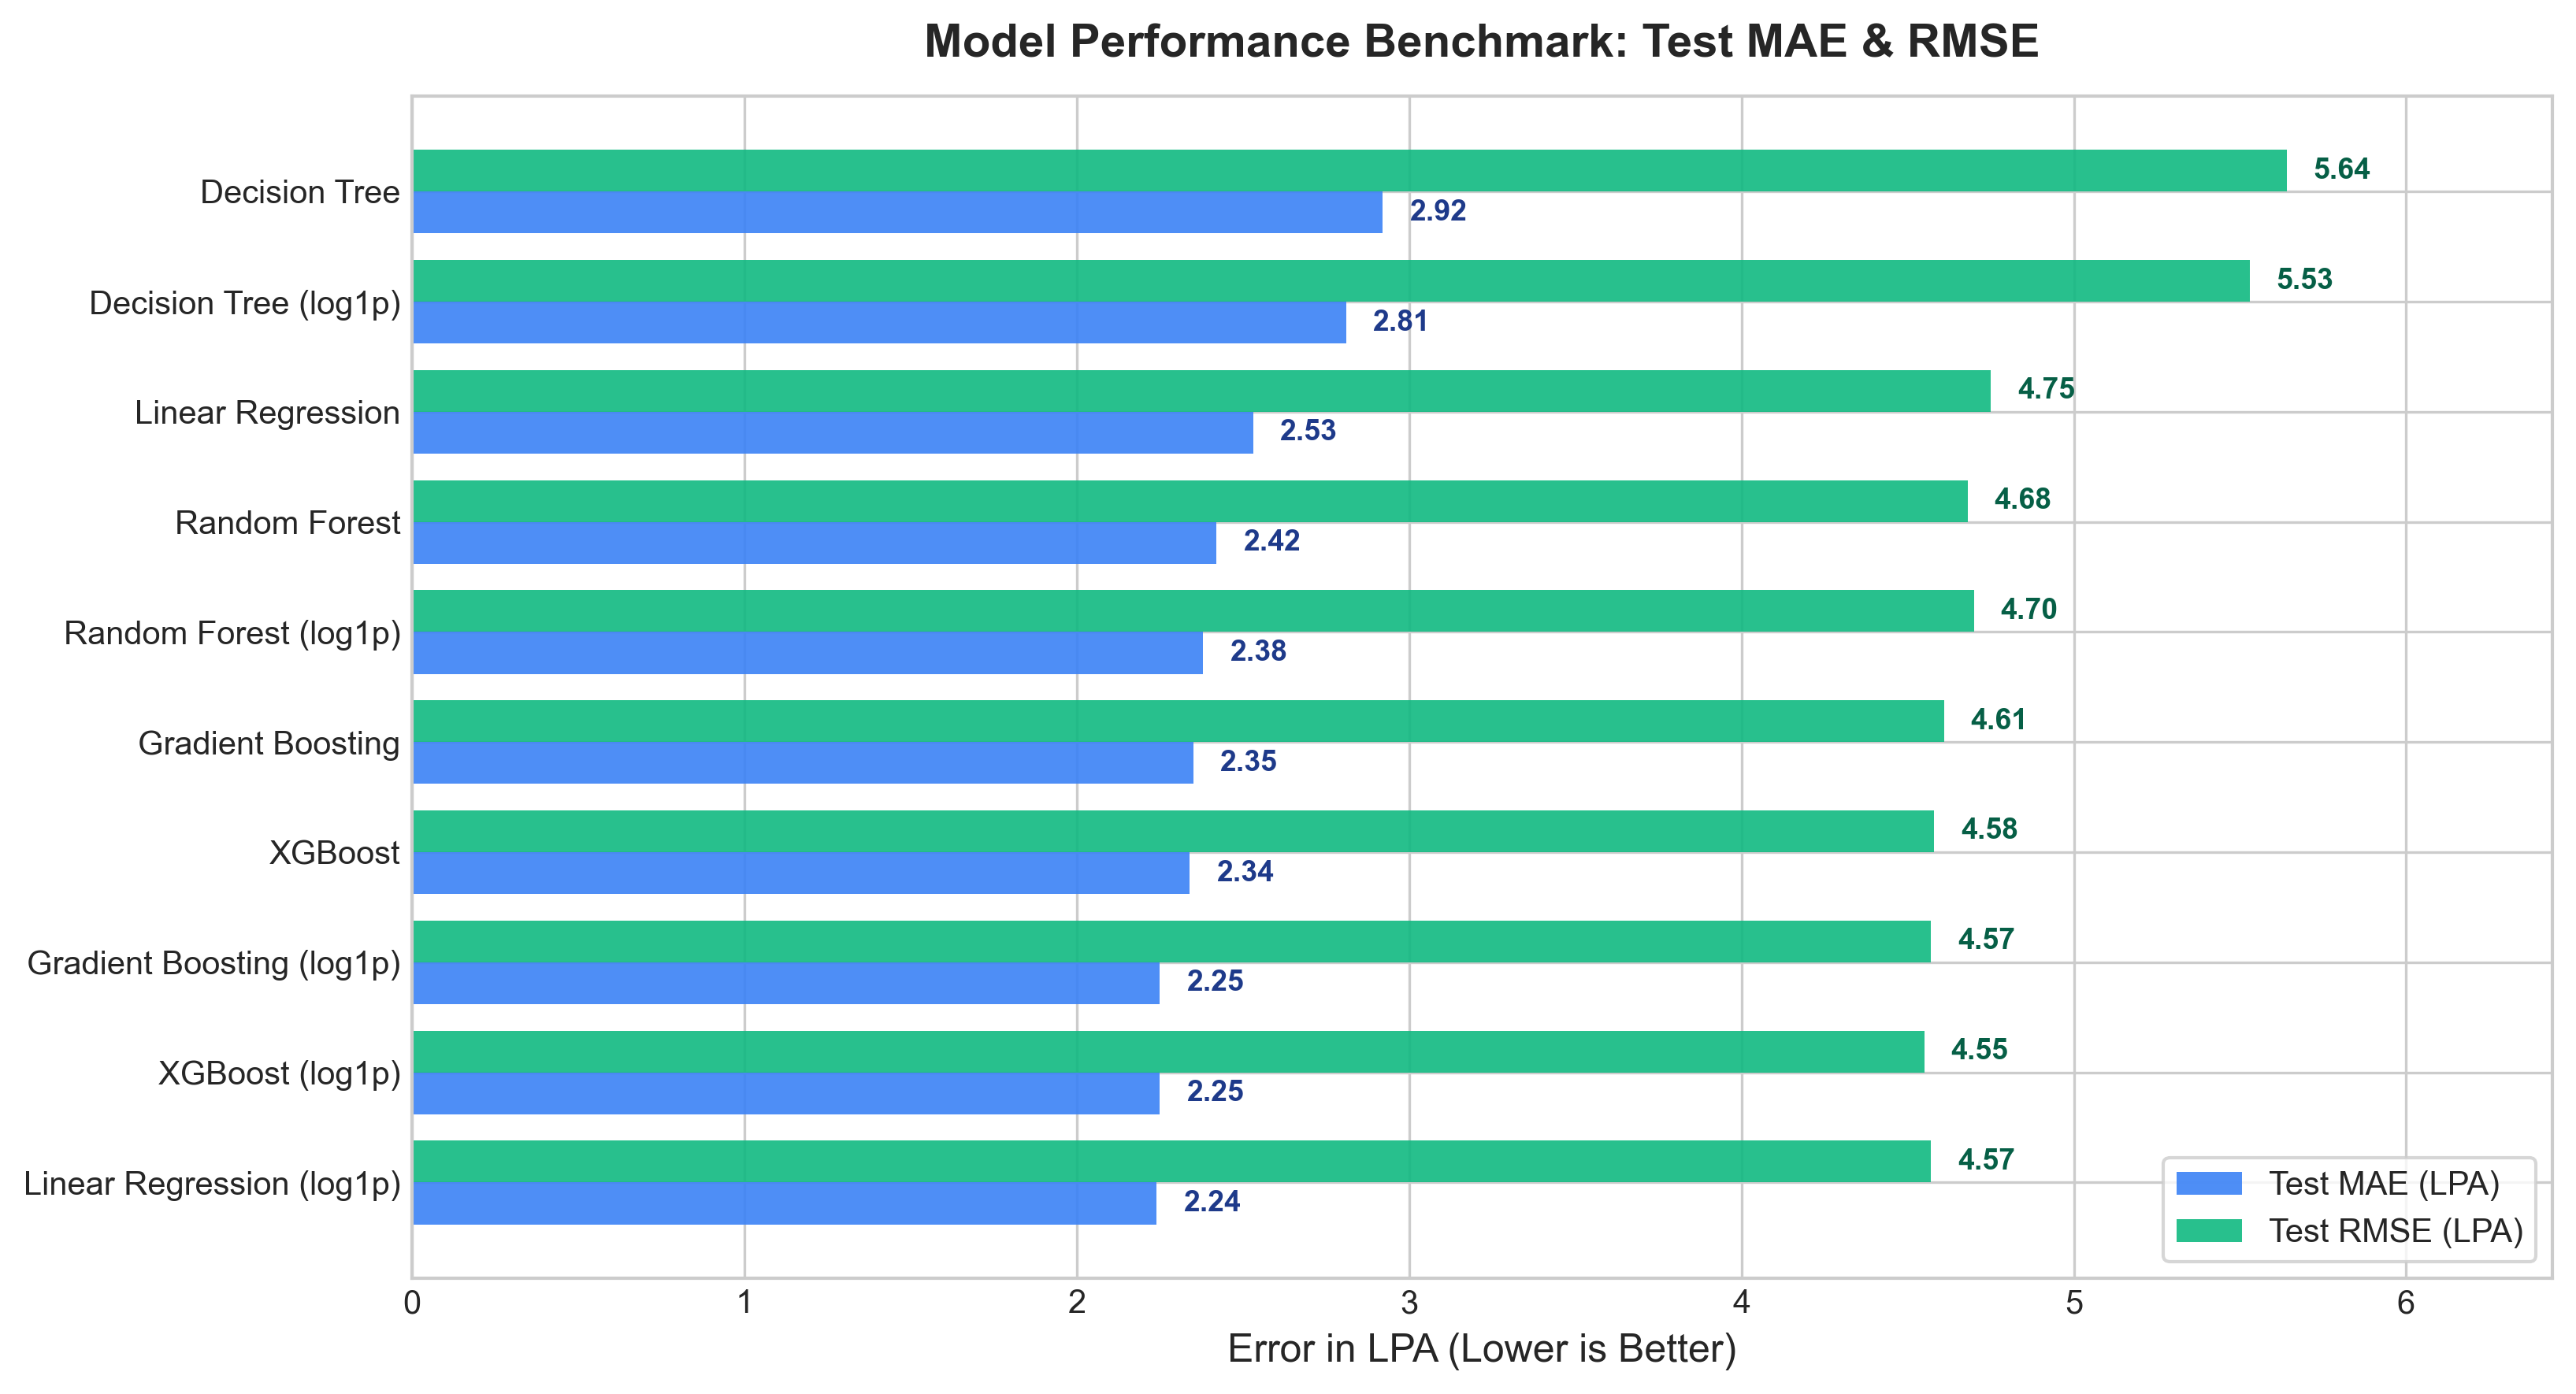

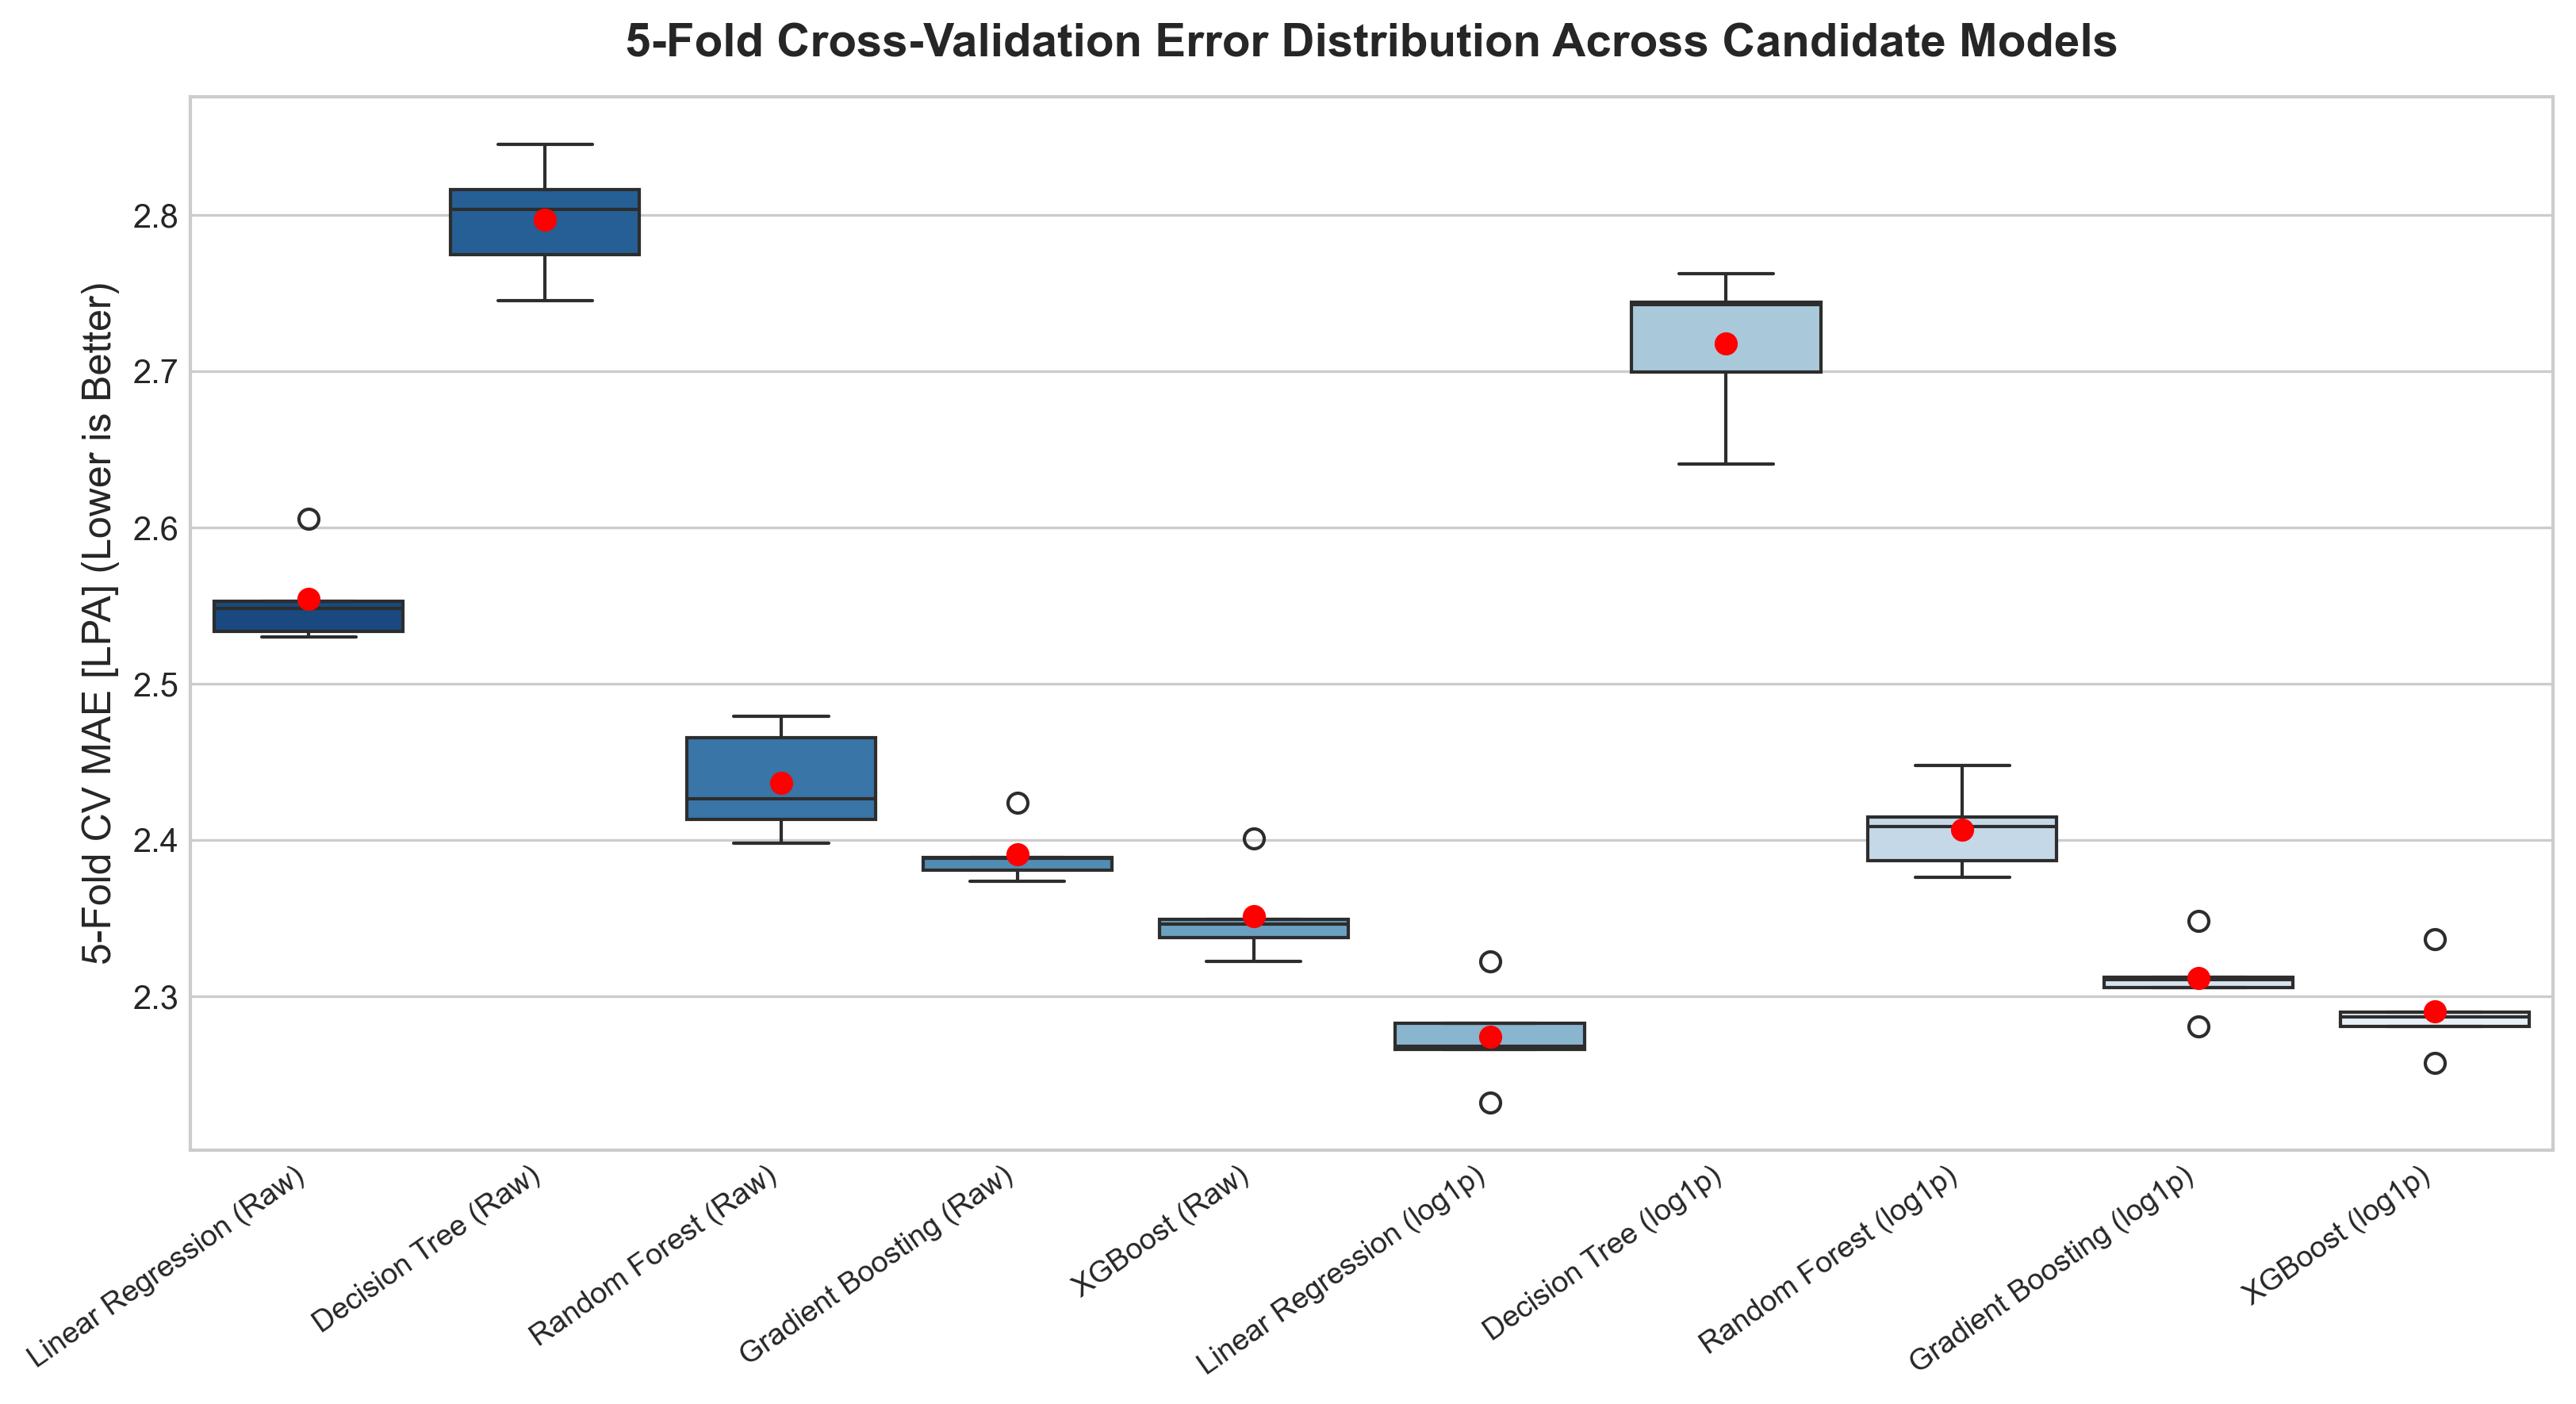

In [5]:
# Figure 4: Model Performance Comparison
fig, ax = plt.subplots(figsize=(11, 6), dpi=300)
comp_plot_df = comparison_df.sort_values(by='Test MAE (LPA)', ascending=True)
y_indices = np.arange(len(comp_plot_df))
bar_width = 0.38

ax.barh(y_indices - bar_width/2, comp_plot_df['Test MAE (LPA)'], height=bar_width, label='Test MAE (LPA)', color='#3B82F6', alpha=0.9)
ax.barh(y_indices + bar_width/2, comp_plot_df['Test RMSE (LPA)'], height=bar_width, label='Test RMSE (LPA)', color='#10B981', alpha=0.9)
ax.set_yticks(y_indices)
ax.set_yticklabels(comp_plot_df['Model'], fontsize=10)
ax.set_xlabel('Error in LPA (Lower is Better)', fontsize=12)
ax.set_title('Model Performance Benchmark: Test MAE & RMSE', fontsize=14, fontweight='bold', pad=12)
ax.legend(frameon=True, facecolor='white', loc='lower right')
for i, v in enumerate(comp_plot_df['Test MAE (LPA)']):
    ax.text(v + 0.08, i - bar_width/2, f'{v:.2f}', va='center', fontsize=9, fontweight='bold', color='#1E3A8A')
for i, v in enumerate(comp_plot_df['Test RMSE (LPA)']):
    ax.text(v + 0.08, i + bar_width/2, f'{v:.2f}', va='center', fontsize=9, fontweight='bold', color='#065F46')
ax.set_xlim(0, max(comp_plot_df['Test RMSE (LPA)']) + 0.8)
plt.tight_layout()
fig.savefig(os.path.join(figures_dir, 'model_performance_comparison.png'))
plt.show()

# Figure 6: Cross-Validation Error Spread
fig, ax = plt.subplots(figsize=(11, 6), dpi=300)
cv_df_plot = pd.DataFrame(cv_box_data)
sns.boxplot(data=cv_df_plot, ax=ax, palette='Blues_r', showmeans=True, meanprops={'marker':'o', 'markerfacecolor':'red', 'markeredgecolor':'red'})
ax.set_xticks(range(len(cv_df_plot.columns)))
ax.set_xticklabels(cv_df_plot.columns, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('5-Fold CV MAE [LPA] (Lower is Better)', fontsize=12)
ax.set_title('5-Fold Cross-Validation Error Distribution Across Candidate Models', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
fig.savefig(os.path.join(figures_dir, 'cross_validation_performance.png'))
plt.show()

### 6. Hyperparameter Optimization (XGBoost with Log-Target)
Executing `RandomizedSearchCV` across tree depth, learning rate, subsample, colsample_bytree, and minimum child weight.

In [6]:
param_distributions = {
    'regressor__n_estimators': [120, 160, 200, 250],
    'regressor__max_depth': [4, 5, 6, 7],
    'regressor__learning_rate': [0.03, 0.05, 0.08, 0.1],
    'regressor__subsample': [0.75, 0.85, 0.95],
    'regressor__colsample_bytree': [0.75, 0.85, 0.95],
    'regressor__min_child_weight': [1, 3, 5],
}

base_ttr_xgb = TransformedTargetRegressor(
    regressor=XGBRegressor(random_state=42, n_jobs=-1),
    func=np.log1p,
    inverse_func=np.expm1
)

random_search = RandomizedSearchCV(
    estimator=base_ttr_xgb,
    param_distributions=param_distributions,
    n_iter=15,
    scoring='neg_mean_absolute_error',
    cv=kf,
    random_state=42,
    n_jobs=-1,
    verbose=0
)

random_search.fit(X_train_trans, y_train)
best_tuned_model = random_search.best_estimator_
best_params = {k.replace('regressor__', ''): v for k, v in random_search.best_params_.items()}

# Evaluate tuned model on test set
y_pred_tuned = best_tuned_model.predict(X_test_trans)
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_mse = mean_squared_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_pred_tuned)
residuals = y_test - y_pred_tuned
residual_std = float(np.std(residuals))

print('=== Optimal Hyperparameters ===')
for param, val in best_params.items():
    print(f'  {param}: {val}')

print(f'\nTuned XGBoost Test Performance:')
print(f'  Test MAE:  {tuned_mae:.2f} LPA')
print(f'  Test RMSE: {tuned_rmse:.2f} LPA')
print(f'  Test R2:   {tuned_r2:.4f}')
print(f'  Residual Std Dev: {residual_std:.2f} LPA')

=== Optimal Hyperparameters ===
  subsample: 0.85
  n_estimators: 200
  min_child_weight: 3
  max_depth: 4
  learning_rate: 0.08
  colsample_bytree: 0.95

Tuned XGBoost Test Performance:
  Test MAE:  2.25 LPA
  Test RMSE: 4.55 LPA
  Test R2:   0.6250
  Residual Std Dev: 4.53 LPA


### 7. Feature Importance & Model Interpretability
Extracting and ranking feature importance weights from the tuned XGBoost regressor.

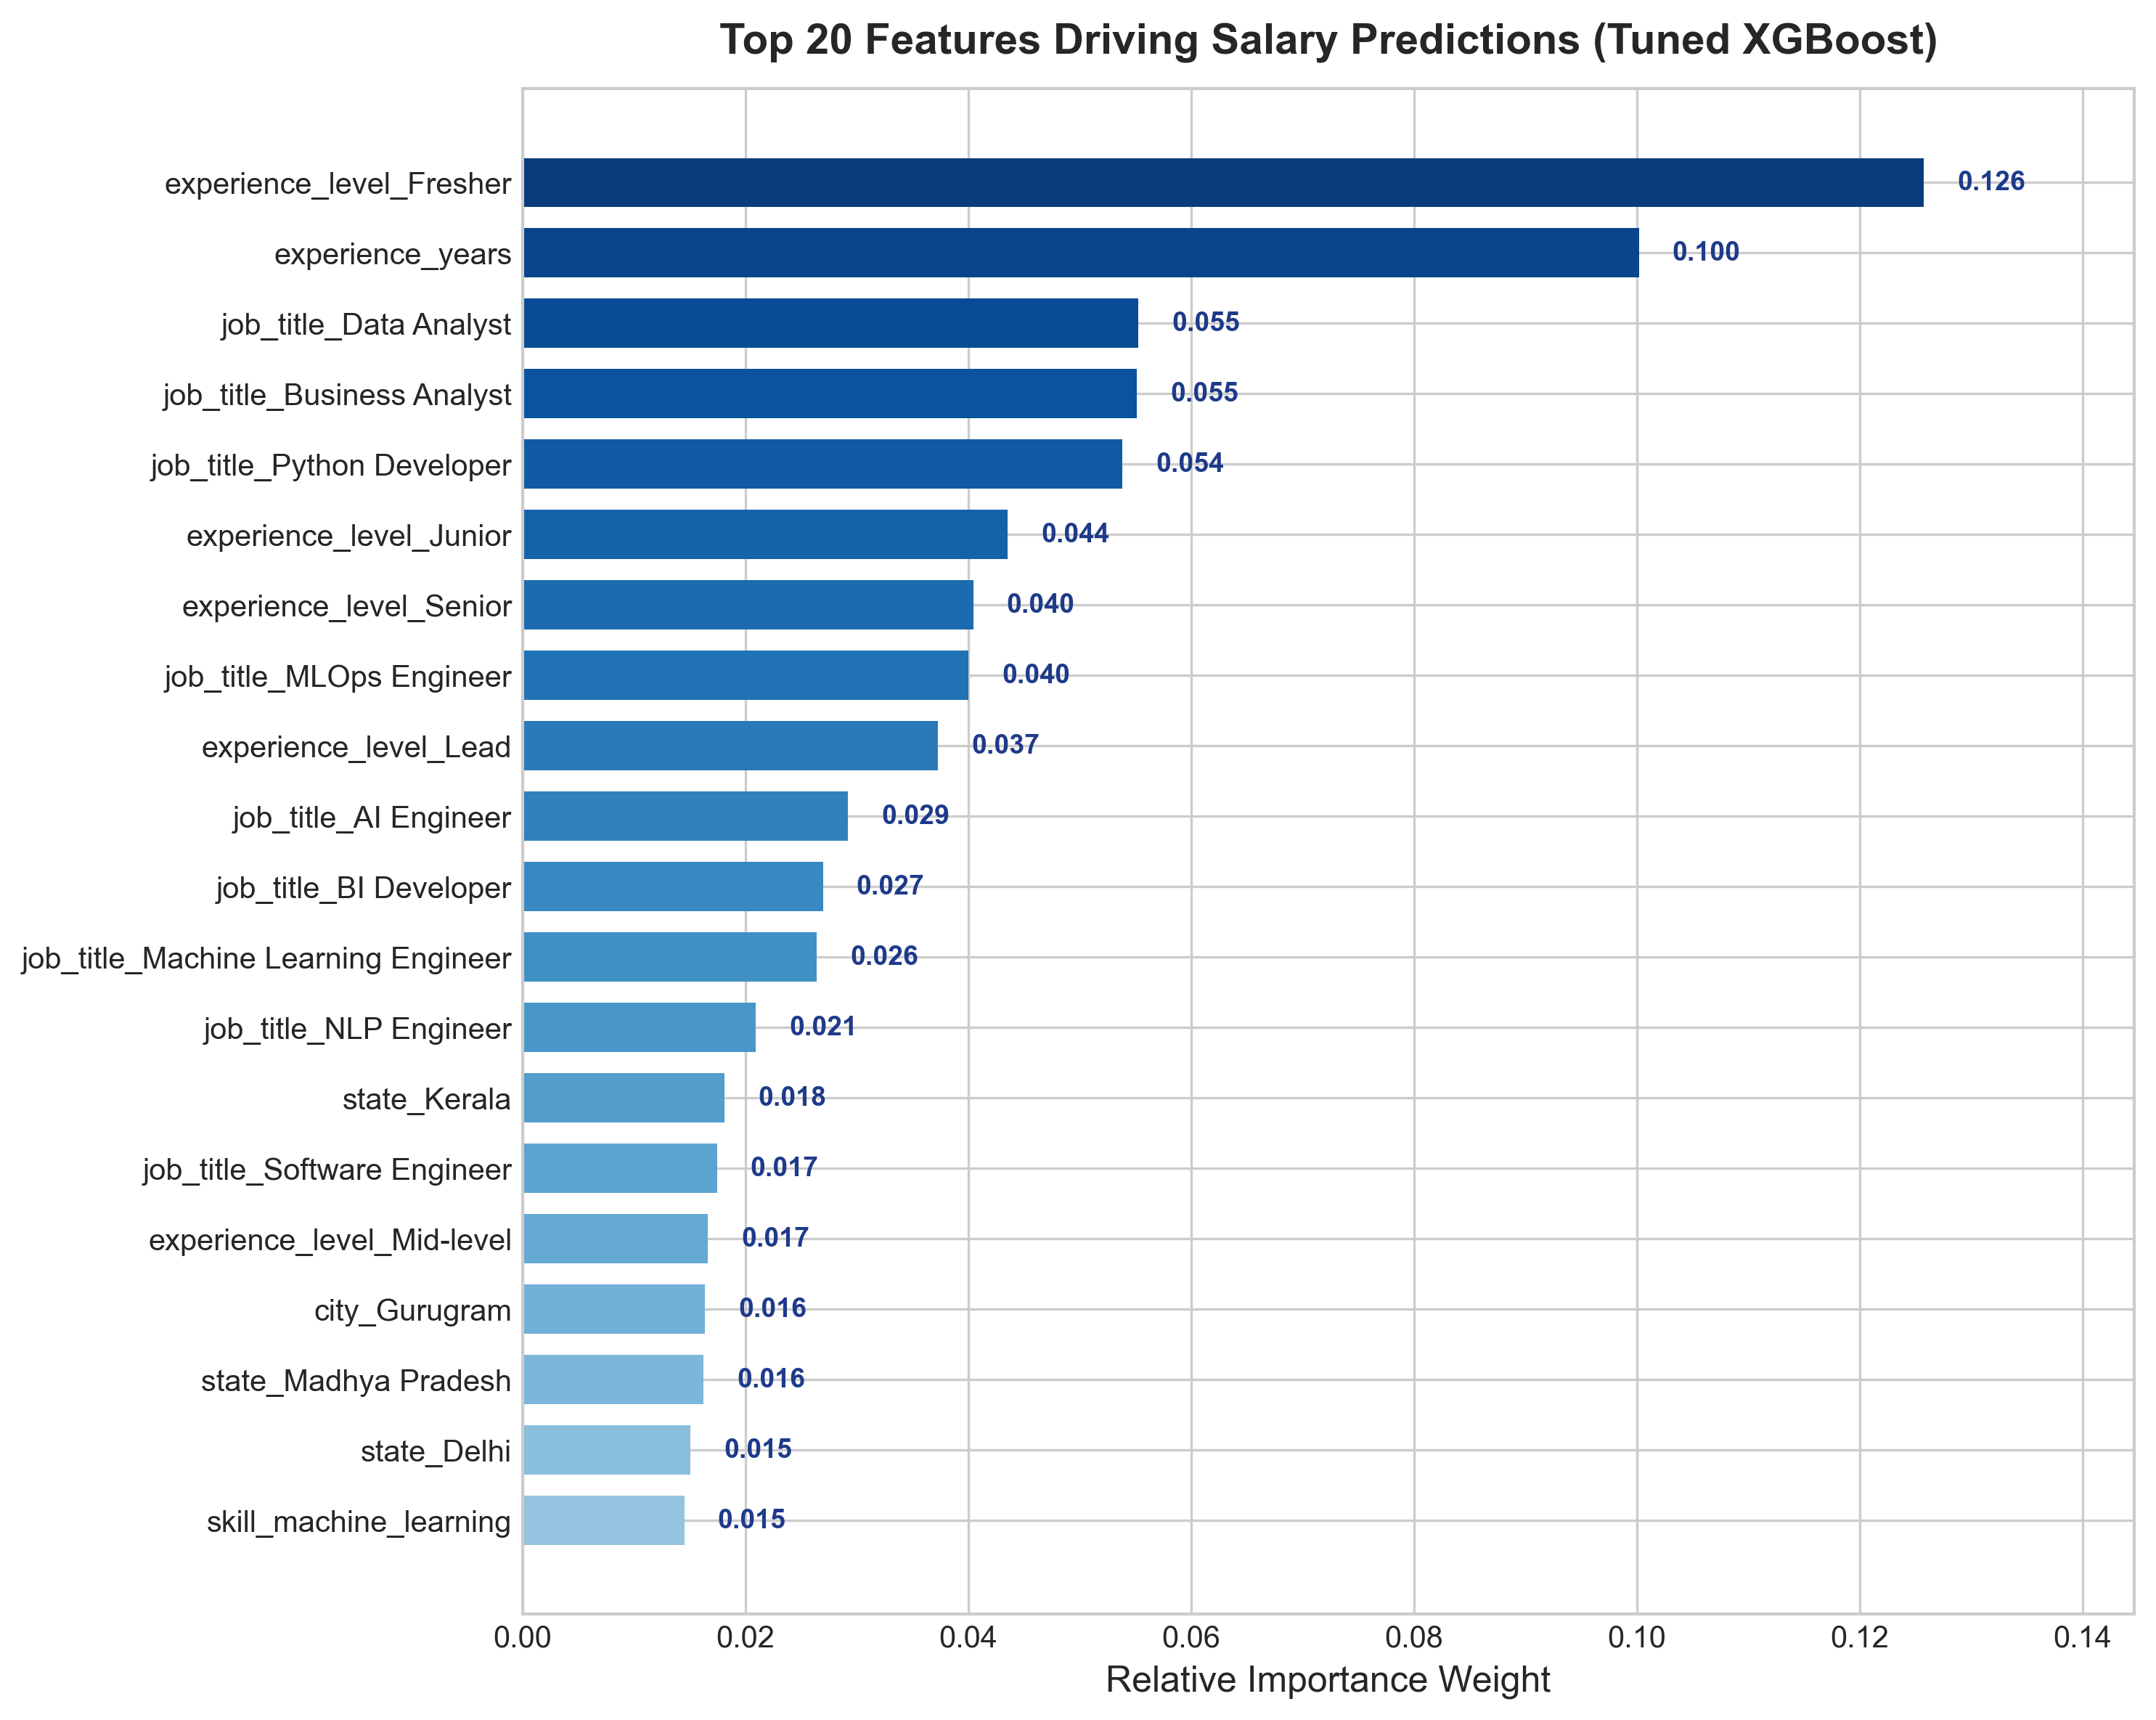

Top 15 Most Influential Features:


,Feature,Importance
0,experience_level_Fresher,0.13
1,experience_years,0.10
2,job_title_Data Analyst,0.06
3,job_title_Business Analyst,0.06
4,job_title_Python Developer,0.05
5,experience_level_Junior,0.04
6,experience_level_Senior,0.04
7,job_title_MLOps Engineer,0.04
8,experience_level_Lead,0.04
9,job_title_AI Engineer,0.03


In [7]:
underlying_xgb = best_tuned_model.regressor_
importances = underlying_xgb.feature_importances_
fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Figure 5: Feature Importance
fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
top_20_fi = fi_df.head(20).sort_values(by='Importance', ascending=True)
colors = plt.cm.Blues(np.linspace(0.4, 0.95, len(top_20_fi)))
bars = ax.barh(top_20_fi['Feature'], top_20_fi['Importance'], color=colors, edgecolor='none', height=0.7)
ax.set_xlabel('Relative Importance Weight', fontsize=12)
ax.set_title('Top 20 Features Driving Salary Predictions (Tuned XGBoost)', fontsize=14, fontweight='bold', pad=12)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.003, bar.get_y() + bar.get_height()/2, f'{w:.3f}', va='center', fontsize=9, fontweight='bold', color='#1E3A8A')
ax.set_xlim(0, max(top_20_fi['Importance']) * 1.15)
plt.tight_layout()
fig.savefig(os.path.join(figures_dir, 'feature_importance.png'))
plt.show()

print('Top 15 Most Influential Features:')
fi_df.head(15)

### 8. Residual Diagnostics & Error Analysis
Evaluating model linearity, normality of residuals, and heteroscedasticity across the salary continuum.

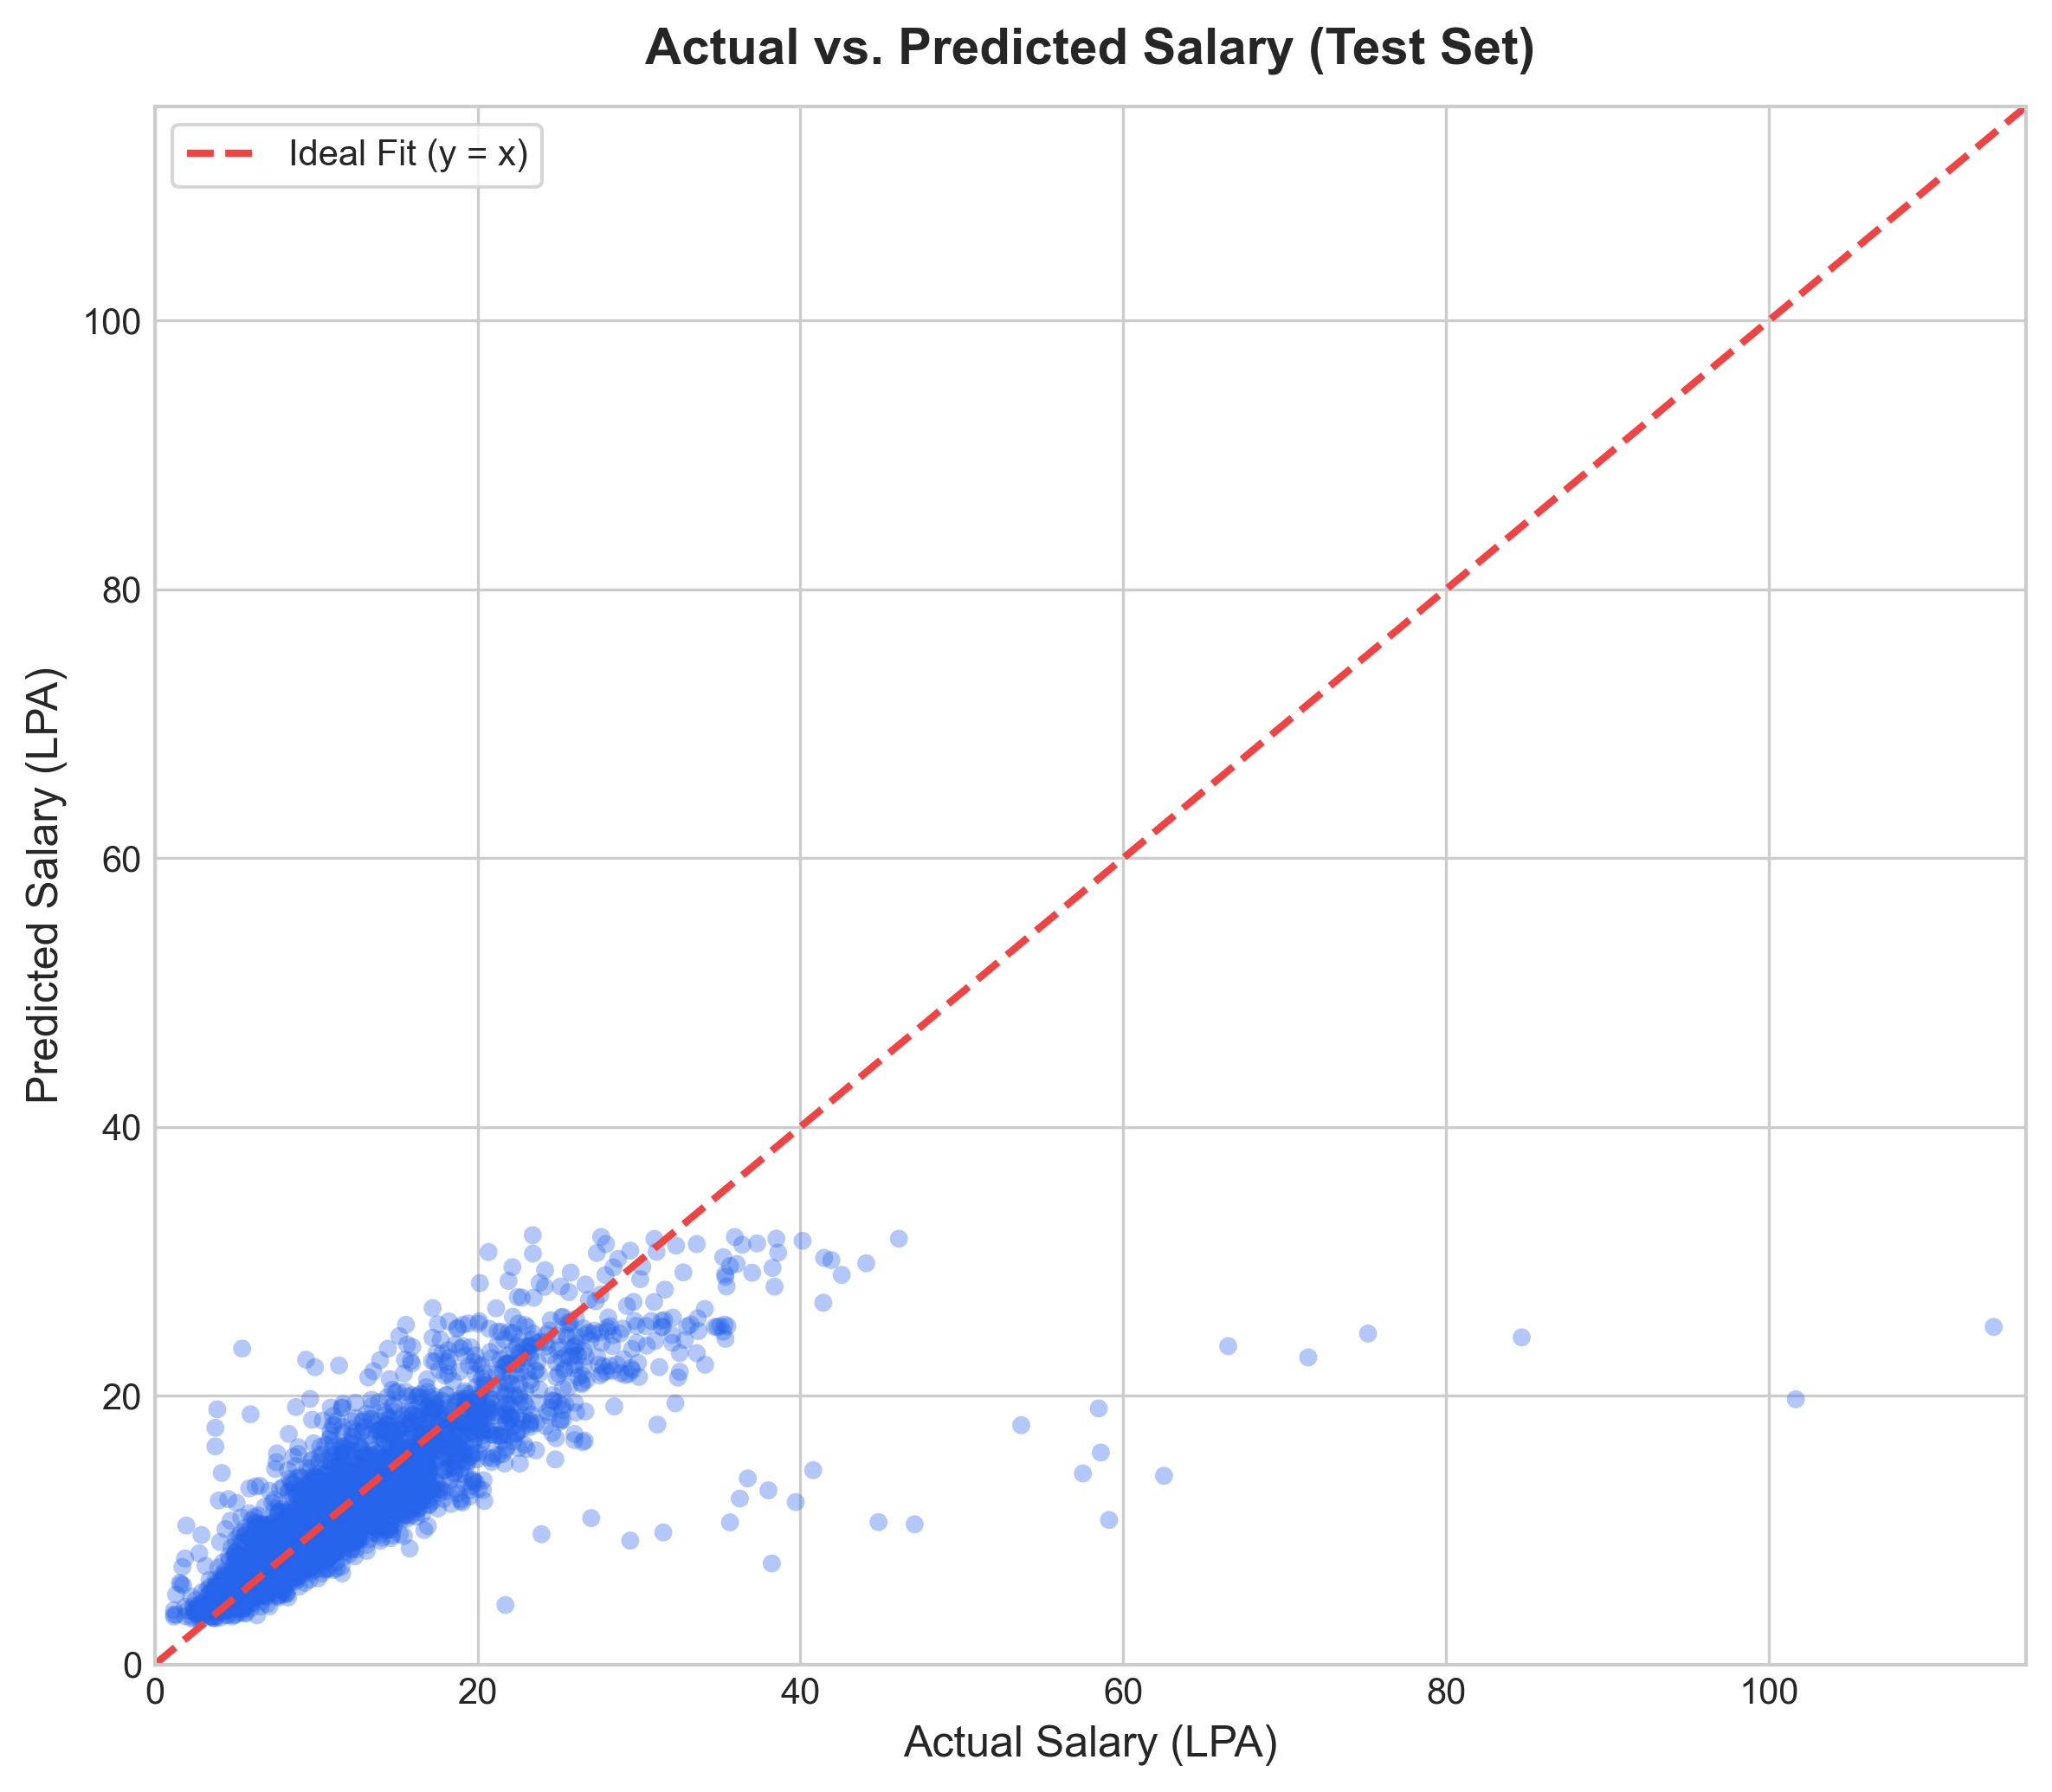

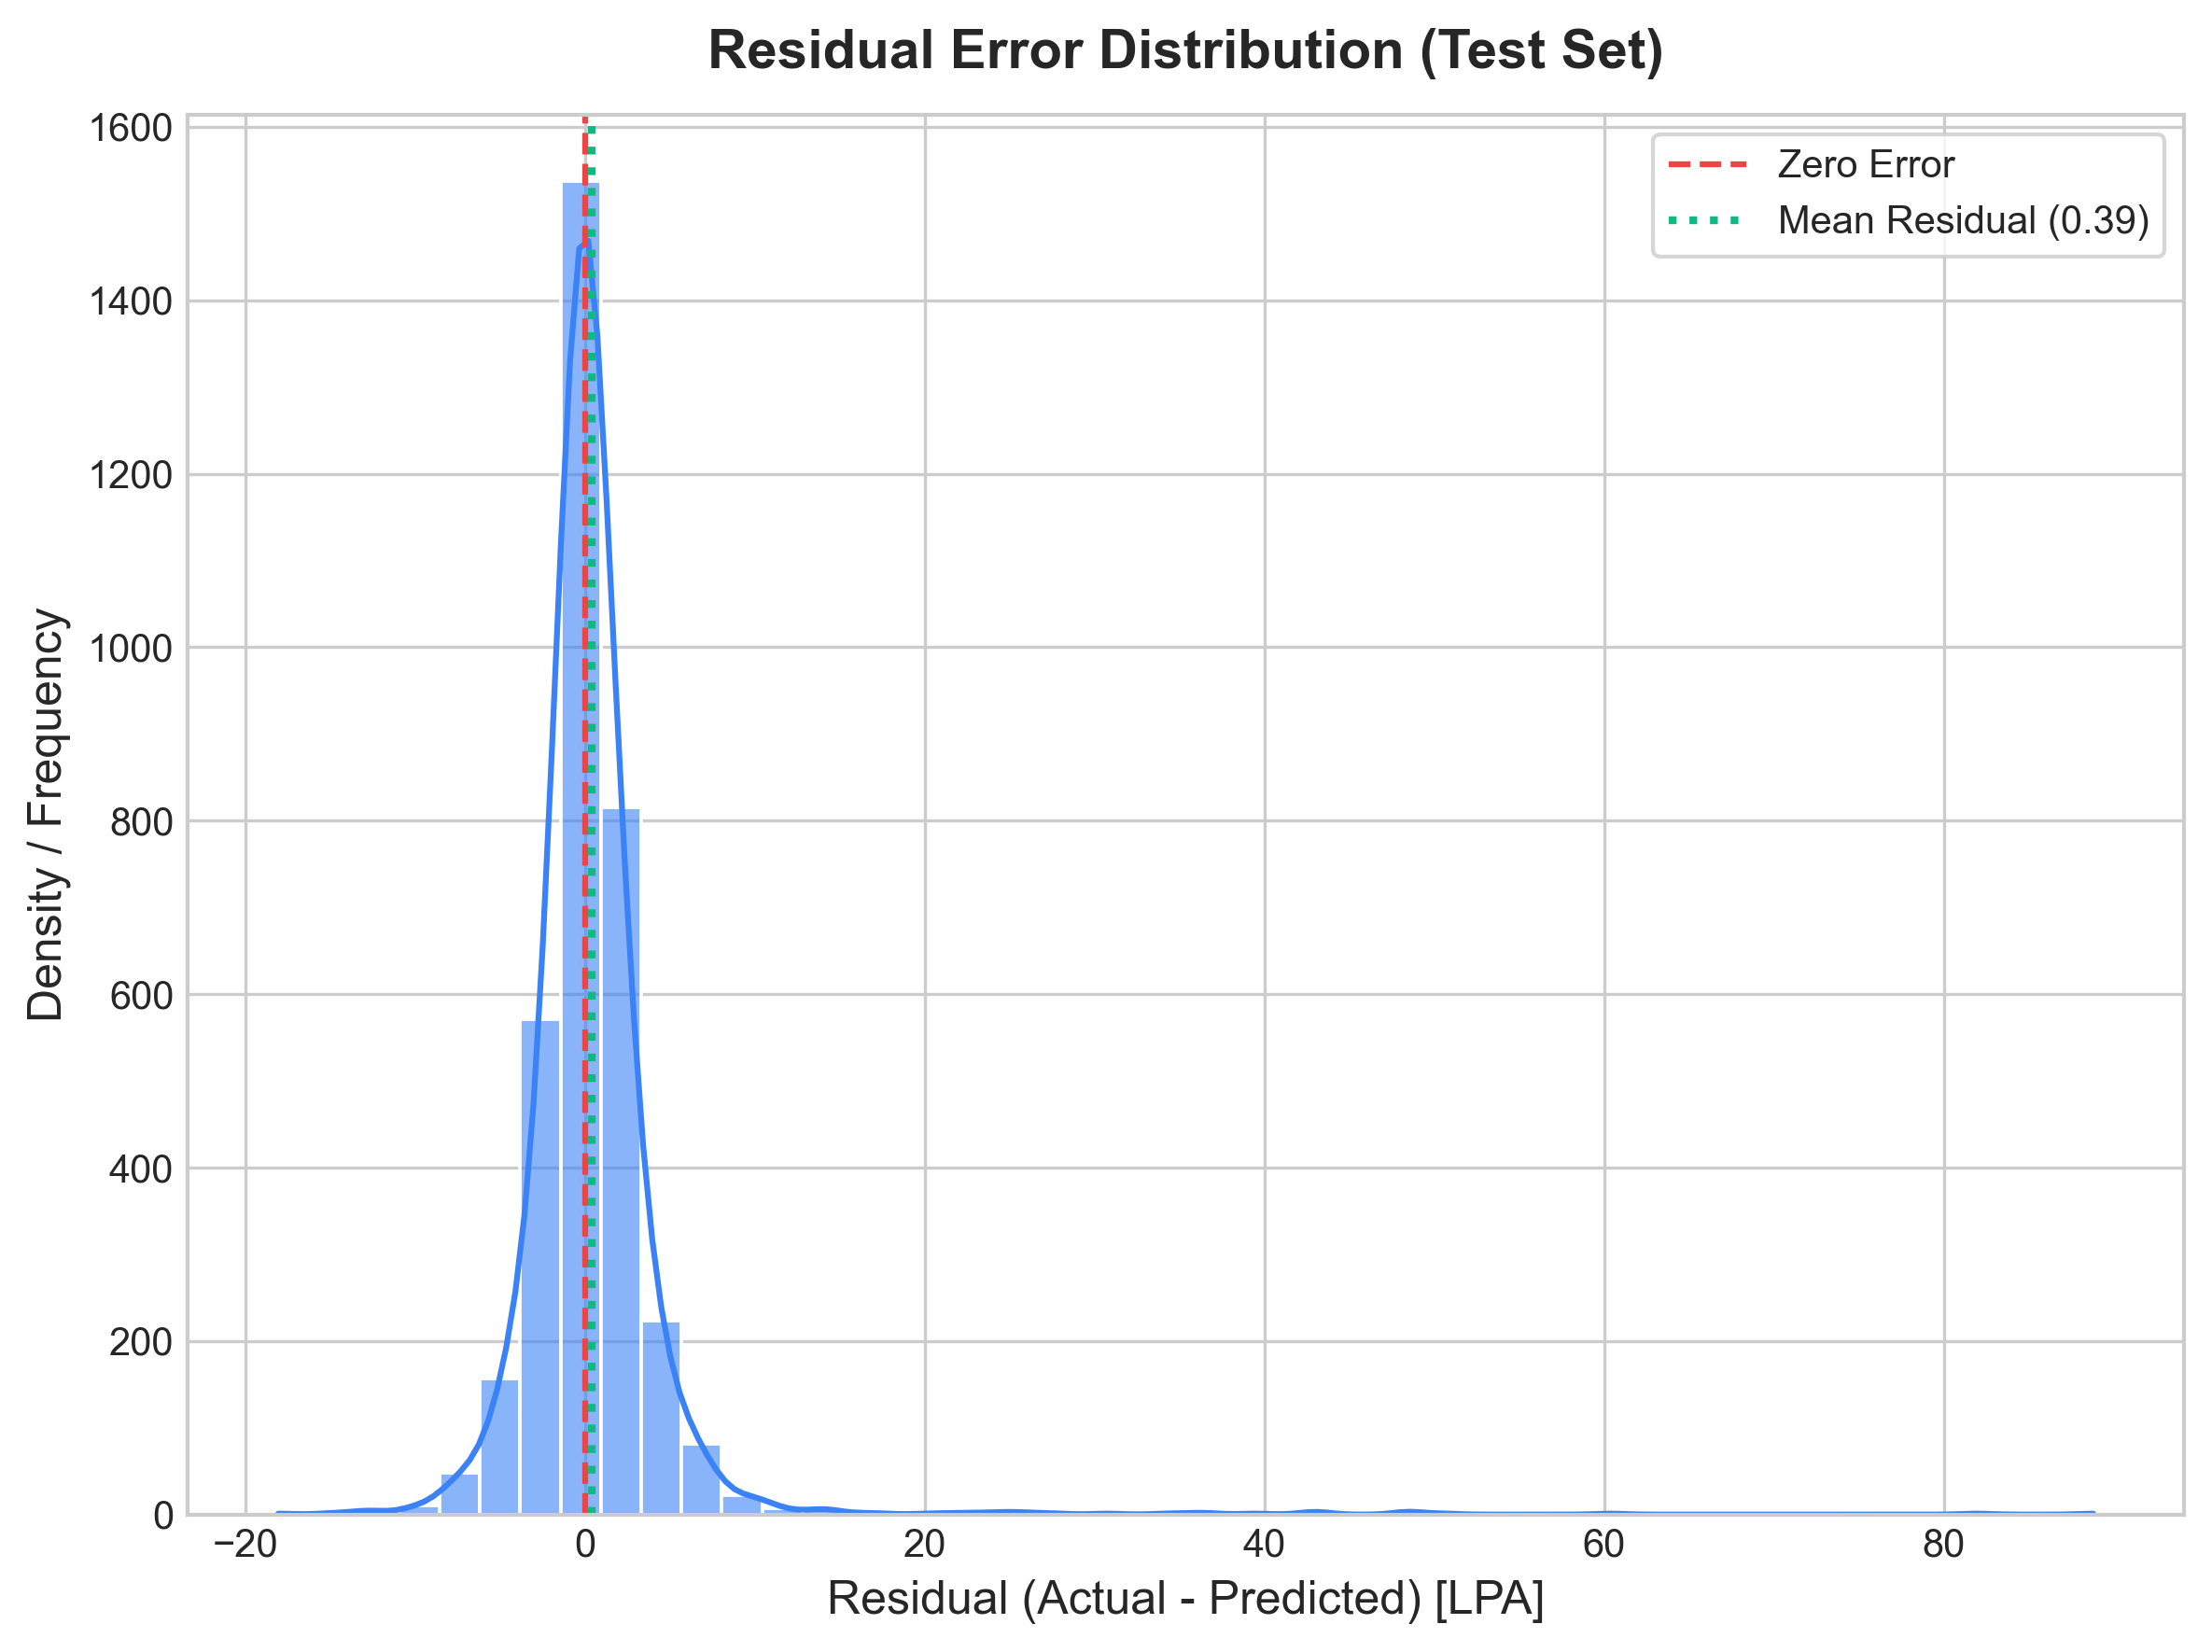

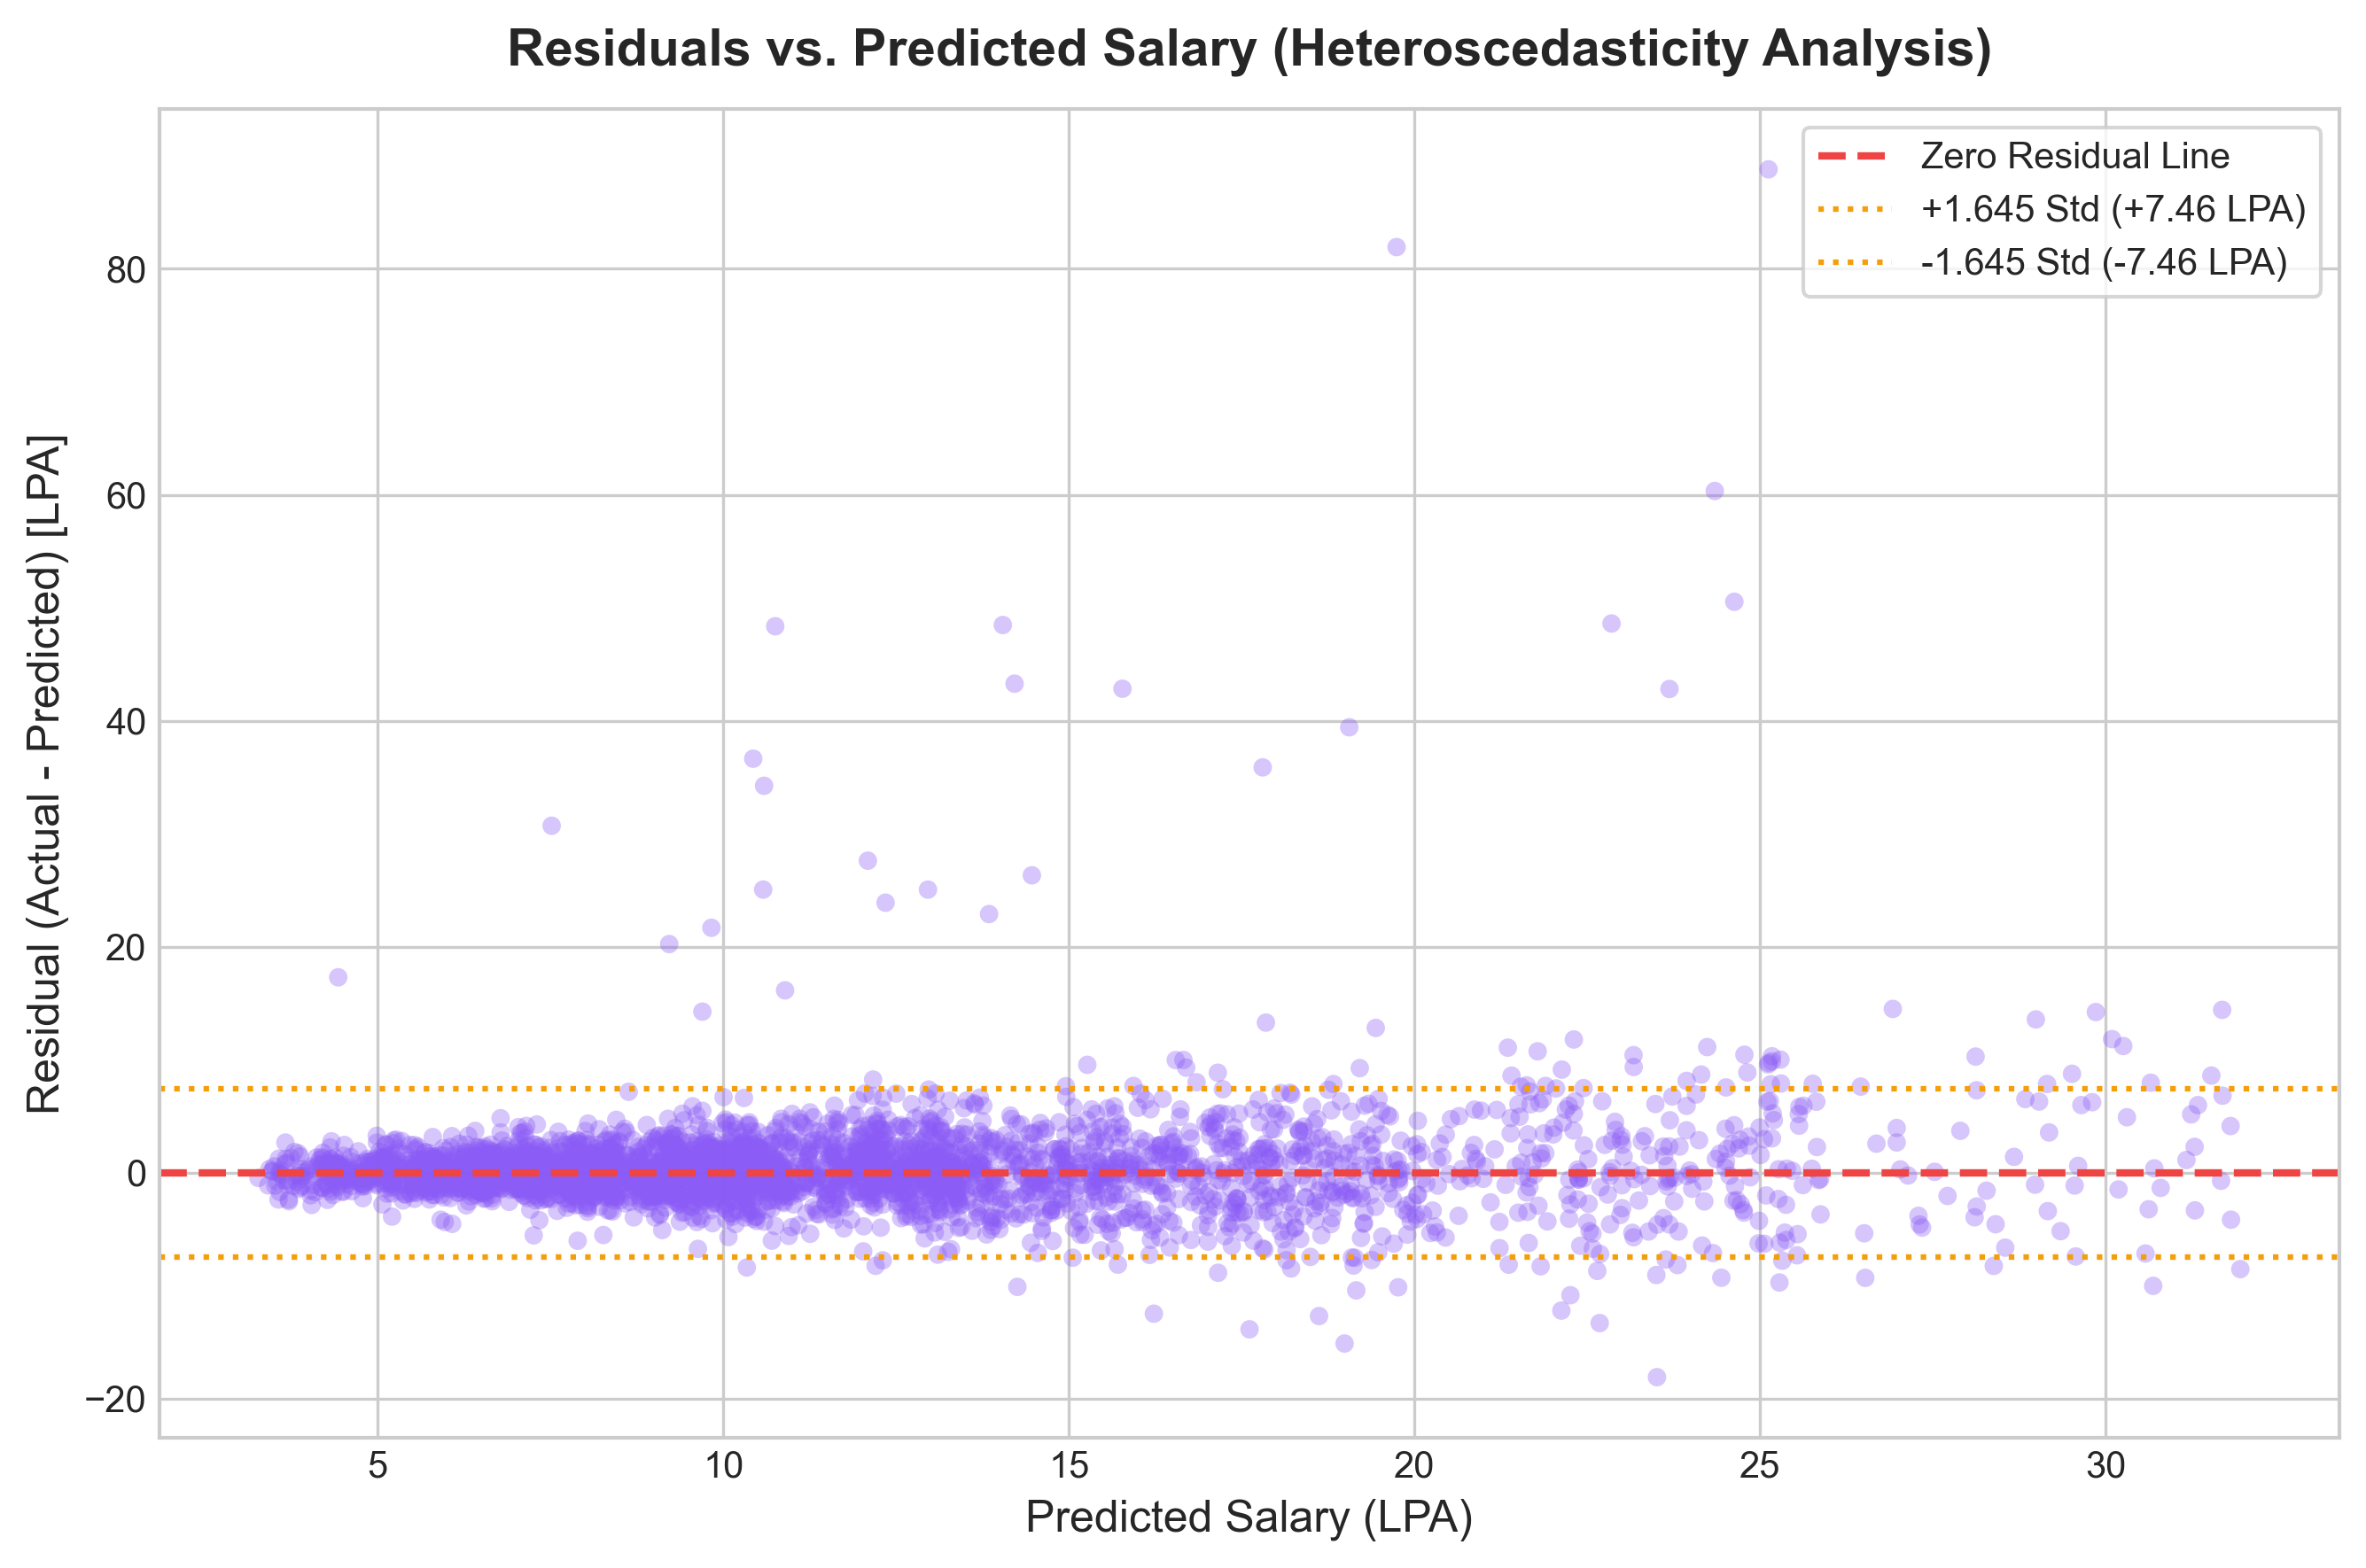

In [8]:
# Figure 1: Actual vs Predicted
fig, ax = plt.subplots(figsize=(8, 7), dpi=300)
ax.scatter(y_test, y_pred_tuned, alpha=0.35, color='#2563EB', edgecolors='none', s=25)
lims = [0, max(max(y_test), max(y_pred_tuned)) + 2]
ax.plot(lims, lims, color='#EF4444', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_title('Actual vs. Predicted Salary (Test Set)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Actual Salary (LPA)', fontsize=12)
ax.set_ylabel('Predicted Salary (LPA)', fontsize=12)
ax.legend(frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
fig.savefig(os.path.join(figures_dir, 'actual_vs_predicted.png'))
plt.show()

# Figure 2: Residual Distribution
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
sns.histplot(residuals, kde=True, color='#3B82F6', bins=45, ax=ax, edgecolor='white', alpha=0.6)
ax.axvline(0, color='#EF4444', linestyle='--', linewidth=1.5, label='Zero Error')
ax.axvline(np.mean(residuals), color='#10B981', linestyle=':', linewidth=2, label=f'Mean Residual ({np.mean(residuals):.2f})')
ax.set_title('Residual Error Distribution (Test Set)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Residual (Actual - Predicted) [LPA]', fontsize=12)
ax.set_ylabel('Density / Frequency', fontsize=12)
ax.legend(frameon=True, facecolor='white')
plt.tight_layout()
fig.savefig(os.path.join(figures_dir, 'residual_distribution.png'))
plt.show()

# Figure 3: Residuals vs Predicted
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)
ax.scatter(y_pred_tuned, residuals, alpha=0.35, color='#8B5CF6', edgecolors='none', s=25)
ax.axhline(0, color='#EF4444', linestyle='--', linewidth=2, label='Zero Residual Line')
ax.axhline(1.645 * residual_std, color='#F59E0B', linestyle=':', linewidth=1.5, label=f'+1.645 Std (+{1.645*residual_std:.2f} LPA)')
ax.axhline(-1.645 * residual_std, color='#F59E0B', linestyle=':', linewidth=1.5, label=f'-1.645 Std (-{1.645*residual_std:.2f} LPA)')
ax.set_title('Residuals vs. Predicted Salary (Heteroscedasticity Analysis)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Predicted Salary (LPA)', fontsize=12)
ax.set_ylabel('Residual (Actual - Predicted) [LPA]', fontsize=12)
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
fig.savefig(os.path.join(figures_dir, 'residuals_vs_predicted.png'))
plt.show()

### 9. Slice-Level Error Analysis
Evaluating prediction error variations across Job Roles and Seniority Tiers.

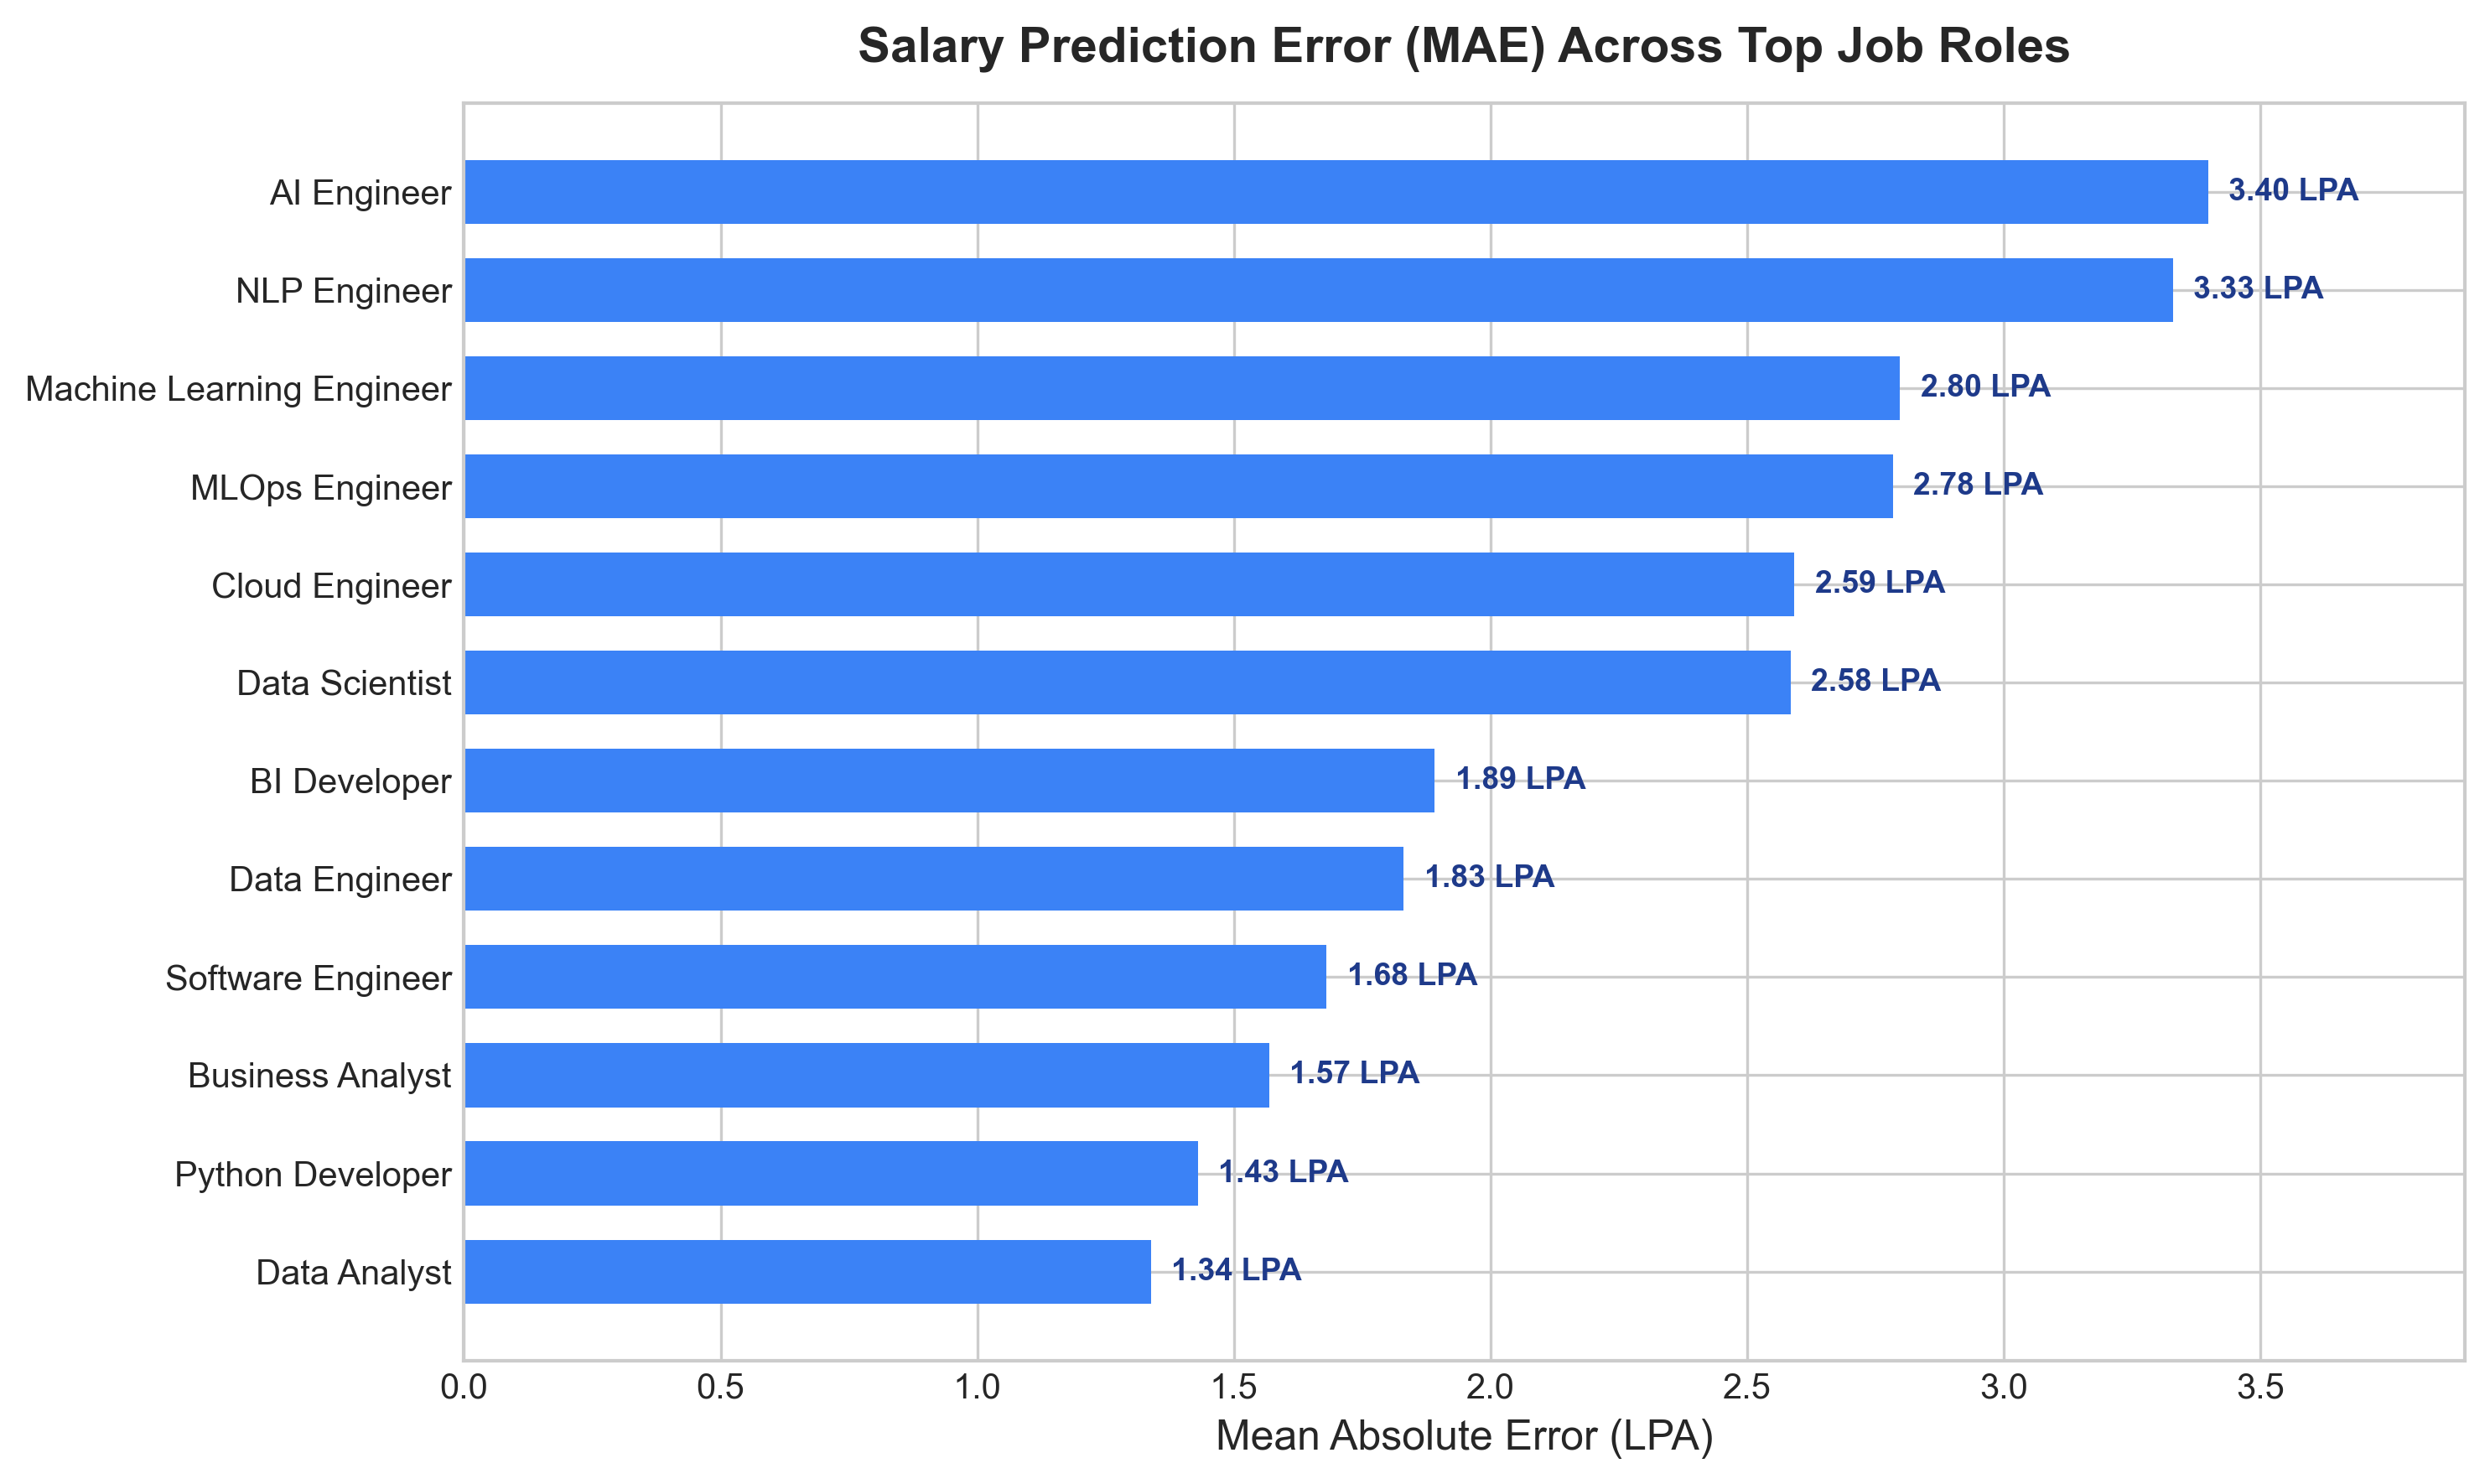

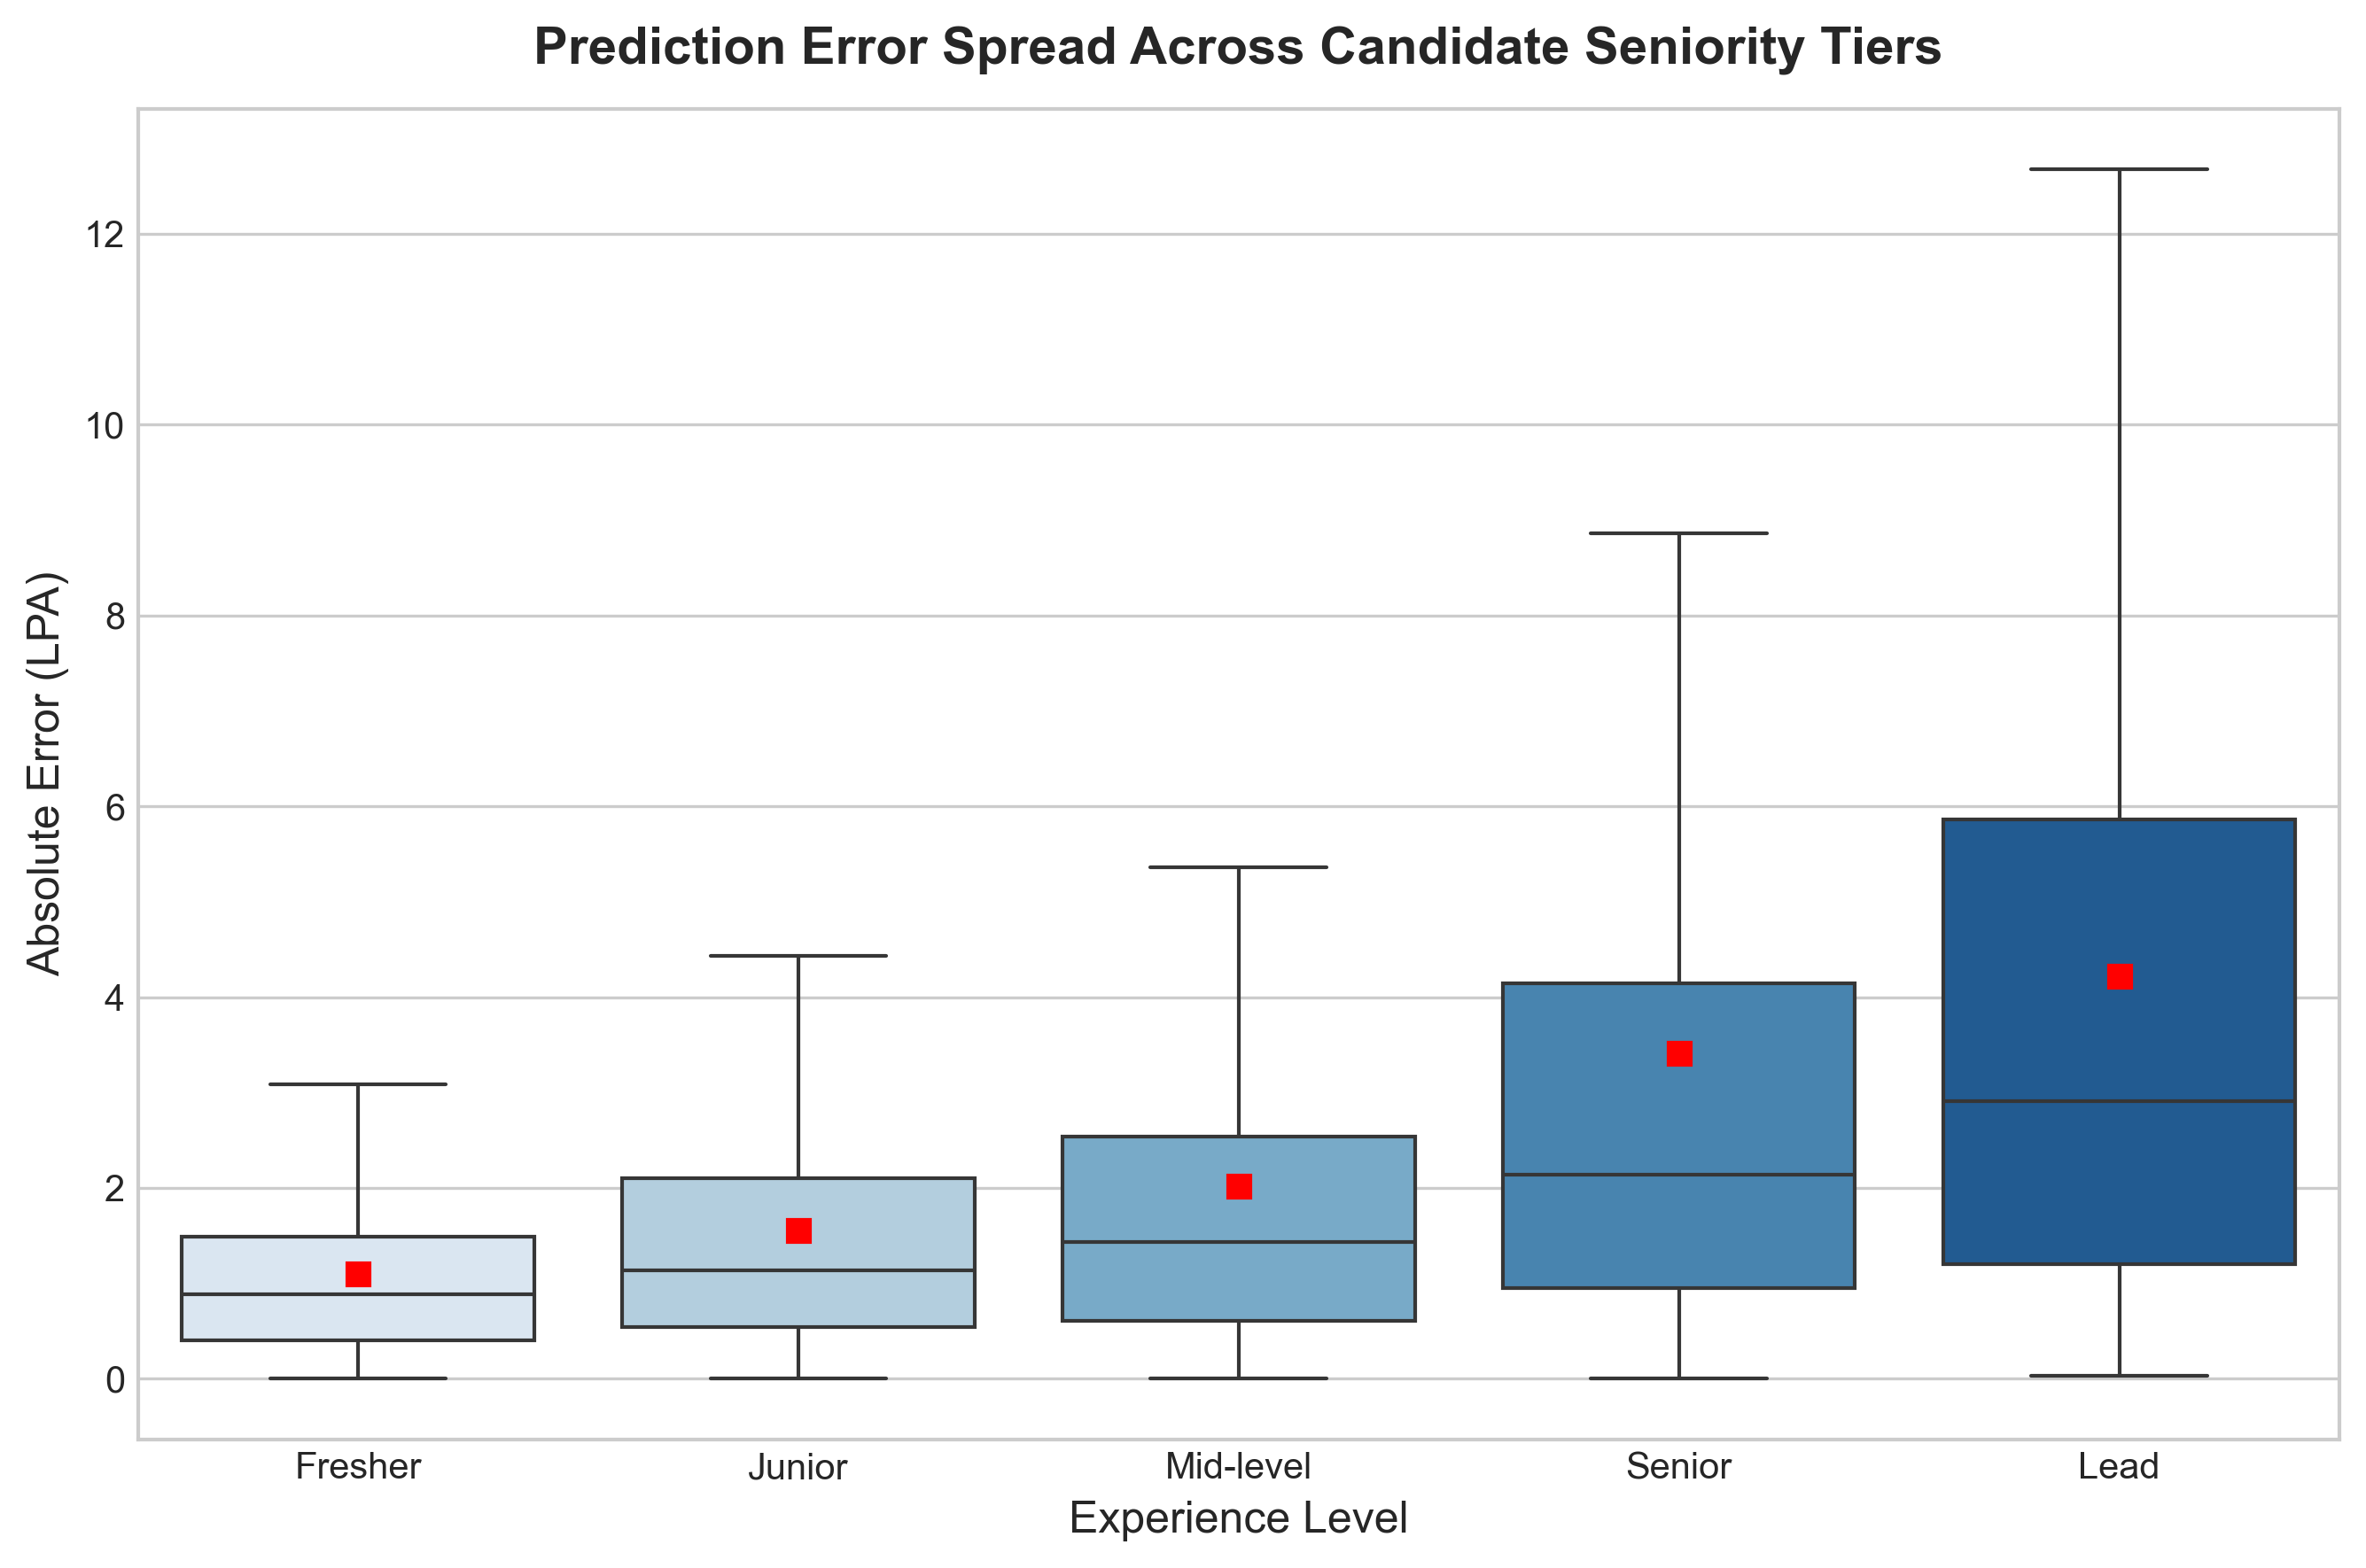

In [9]:
test_eval_df = X_test.copy()
test_eval_df['actual_salary'] = y_test
test_eval_df['predicted_salary'] = y_pred_tuned
test_eval_df['abs_error'] = np.abs(y_test - y_pred_tuned)

# Figure 7: Errors by Job Role
top_roles = test_eval_df['job_title'].value_counts().head(12).index
role_errors = test_eval_df[test_eval_df['job_title'].isin(top_roles)].groupby('job_title')['abs_error'].mean().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
bars = ax.barh(role_errors.index, role_errors.values, color='#3B82F6', height=0.65)
ax.set_xlabel('Mean Absolute Error (LPA)', fontsize=12)
ax.set_title('Salary Prediction Error (MAE) Across Top Job Roles', fontsize=14, fontweight='bold', pad=12)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.04, bar.get_y() + bar.get_height()/2, f'{w:.2f} LPA', va='center', fontsize=9, fontweight='bold', color='#1E3A8A')
ax.set_xlim(0, max(role_errors.values) + 0.5)
plt.tight_layout()
fig.savefig(os.path.join(figures_dir, 'prediction_errors_by_job_role.png'))
plt.show()

# Figure 8: Errors by Experience Level
exp_order = ['Fresher', 'Junior', 'Mid-level', 'Senior', 'Lead']
exp_eval_df = test_eval_df[test_eval_df['experience_level'].isin(exp_order)]

fig, ax = plt.subplots(figsize=(9, 6), dpi=300)
sns.boxplot(x='experience_level', y='abs_error', data=exp_eval_df, order=exp_order, ax=ax, palette='Blues', showfliers=False, showmeans=True, meanprops={'marker':'s', 'markerfacecolor':'red', 'markeredgecolor':'red'})
ax.set_xlabel('Experience Level', fontsize=12)
ax.set_ylabel('Absolute Error (LPA)', fontsize=12)
ax.set_title('Prediction Error Spread Across Candidate Seniority Tiers', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
fig.savefig(os.path.join(figures_dir, 'prediction_errors_by_experience_level.png'))
plt.show()

### 10. Pipeline Assembly & Artifact Serialization
Creating end-to-end `Pipeline([('preprocessor', feature_pipeline), ('regressor', best_tuned_model)])` and persisting artifacts to `models/`.

In [10]:
# 1. Save Best Regressor
joblib.dump(best_tuned_model, os.path.join(models_dir, 'best_salary_model.joblib'))

# 2. Build and save full end-to-end pipeline
full_pipeline = Pipeline([
    ('preprocessor', feature_pipeline),
    ('regressor', best_tuned_model)
])

package = {
    'pipeline': full_pipeline,
    'model_version': '1.0.0',
    'best_model_name': 'Tuned XGBoost Regressor (log1p)',
    'residual_std': round(residual_std, 2),
    'best_params': best_params,
    'disclaimer': LIMITATIONS_DISCLAIMER
}
joblib.dump(package, os.path.join(models_dir, 'salary_prediction_pipeline.joblib'))

# 3. Save comparison table and feature importance
comparison_df.to_csv(os.path.join(models_dir, 'model_comparison.csv'), index=False)
fi_df.to_csv(os.path.join(models_dir, 'feature_importance.csv'), index=False)

# 4. Save metadata JSON
meta_data = {
    'model_version': '1.0.0',
    'best_model_name': 'Tuned XGBoost Regressor (log1p)',
    'target_variable': 'salary_mid_lpa (INR Lakhs Per Annum)',
    'test_mae_lpa': round(tuned_mae, 2),
    'test_mse': round(tuned_mse, 2),
    'test_rmse_lpa': round(tuned_rmse, 2),
    'test_r2': round(tuned_r2, 4),
    'residual_std_lpa': round(residual_std, 2),
    'empirical_confidence_multiplier_90pct': 1.645,
    'total_training_samples': len(y_train),
    'total_test_samples': len(y_test),
    'total_features': len(feature_names),
    'best_hyperparameters': best_params,
    'disclaimer': LIMITATIONS_DISCLAIMER
}
with open(os.path.join(models_dir, 'model_metadata.json'), 'w') as f:
    json.dump(meta_data, f, indent=2)

print('All production artifacts serialized successfully to models/.')

All production artifacts serialized successfully to models/.


### 11. Production Inference Verification
Validating inference on candidate profiles via `SalaryPredictor` and `predict_salary`.

In [11]:
predictor = SalaryPredictor()

# Test candidate 1: Mid-level ML Engineer
res1 = predictor.predict(
    job_title='Machine Learning Engineer',
    experience_years=4.5,
    city='Bengaluru',
    skills=['Python', 'SQL', 'PyTorch', 'AWS', 'Docker'],
    work_mode='Hybrid'
)

print('--- Test Prediction 1: Mid-level ML Engineer ---')
for k, v in res1.items():
    print(f'  {k}: {v}')

# Test candidate 2: Fresher Data Analyst
res2 = predictor.predict(
    job_title='Data Analyst',
    experience_years=0.5,
    city='Pune',
    skills='Excel, SQL, Power BI',
    work_mode='Work from Home'
)

print('\n--- Test Prediction 2: Fresher Data Analyst ---')
print(f'Predicted Salary: {res2["predicted_salary_lpa"]} LPA ({res2["predicted_salary_annual_inr"]:,} INR)')
print(f'Empirical 90% Bounds: [{res2["lower_bound_lpa"]} LPA - {res2["upper_bound_lpa"]} LPA]')
print(f'Disclaimer: {res2["limitations_disclaimer"][:80]}...')

--- Test Prediction 1: Mid-level ML Engineer ---
  predicted_salary_lpa: 15.17
  predicted_salary_annual_inr: 1517000
  lower_bound_lpa: 7.72
  upper_bound_lpa: 22.62
  lower_bound_annual_inr: 772000
  upper_bound_annual_inr: 2262000
  residual_std_lpa: 4.53
  model_version: 1.0.0
  model_name: Tuned XGBoost Regressor (log1p)
  limitations_disclaimer: Salary predictions are statistical estimates derived from disclosed compensation in tech job postings. They represent indicative market compensation benchmarks, not verified employee compensation or contractual guarantees. Actual compensation offers vary according to candidate assessment, organizational budgets, and negotiation.

--- Test Prediction 2: Fresher Data Analyst ---
Predicted Salary: 4.24 LPA (424,000 INR)
Empirical 90% Bounds: [0.5 LPA - 11.69 LPA]
Disclaimer: Salary predictions are statistical estimates derived from disclosed compensation...
